# Question D: When do citations peak, and which papers become "high hitters"?

## Identify peak timing using Kaplan–Meier approach

**Question:** How many years after publication do FSR papers typically peak?

**Framing:** we treat "time to citation peak" as a *duration / survival-analysis* problem rather than a plain descriptive statistic. This is deliberate:

- Papers published recently may not have peaked yet, so we simply don't know their peak age. This is **right-censoring**, and a plain mean/median over *observed* peak ages would be biased downward if we ignored it (we'd be systematically excluding papers whose true peak lies further in the future).
- Kaplan–Meier (KM) is the standard non-parametric way to estimate a time-to-event distribution in the presence of censoring, and it lets us report **quantiles** (e.g. median peak age) with a defensible estimator rather than an ad-hoc average.


### 1.1 Setup

For each paper $i = 1, \dots, N$ define:

- $T_i$: the **age at citation peak** (years since publication), the *event time*, if observed.
- $C_i$: the **censoring time**. For papers that have not yet had the chance to peak (e.g. published too recently, or still on a rising citation trajectory as of the data cut-off), this is how long we've been able to observe them so far.
- $\delta_i \in \{0, 1\}$: event indicator, $\delta_i = 1$ if the peak was actually observed, $\delta_i = 0$ if the paper is censored (we only know it hasn't peaked by $C_i$).
- Observed duration: $X_i = \min(T_i, C_i)$.

So each paper contributes a pair $(X_i, \delta_i)$ to the estimator.

### 1.2 The Kaplan–Meier estimator

Let $t_{(1)} < t_{(2)} < \dots < t_{(k)}$ be the distinct observed **event** times (i.e. distinct peak ages actually seen in the data, ignoring censoring times). At each event time $t_{(j)}$ define:

- $n_j$ = number of papers still **at risk** just before $t_{(j)}$ (i.e. not yet peaked and not yet censored, i.e. durations $\geq t_{(j)}$),
- $d_j$ = number of papers whose peak is observed exactly at $t_{(j)}$.

The Kaplan–Meier estimator of the **survival function**, here the probability that a paper has *not yet peaked* by time $t$, is:

$$
\hat S(t) \;=\; \prod_{j:\, t_{(j)} \le t} \left(1 - \frac{d_j}{n_j}\right)
$$

with $\hat S(t) = 1$ for $t$ before the first event. $\hat S(t)$ is a step function that starts at 1 and drops at each observed peak time; it only ever drops at *event* times, not at censoring times (censored papers simply leave the risk set).

### 1.3 Getting the quantile we actually want

The $p$-th quantile of the peak-age distribution, $t_p$, is defined directly from the estimated survival curve as

$$
t_p \;=\; \inf\{\, t : \hat S(t) \le 1-p \,\}
$$

So the **median peak age** is

$$
t_{0.5} \;=\; \inf\{\, t : \hat S(t) \le 0.5 \,\}
$$

i.e. the first time at which the estimated fraction of papers that have *not yet* peaked drops to (or below) 50%. We'll pull this, and the 25th/75th percentiles for a spread, directly off the fitted KM curve.

*(Variance / confidence intervals on $\hat S(t)$ use Greenwood's formula, which `lifelines` computes automatically; we report the CI bands on the quantiles for completeness.)*


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True


### 1.4 Data

Two files, both expected in the same folder as this notebook:

- **`fsr_citations_by_year_openalex.csv`**: long format, one row per (paper, citation year): `doi`, `fsr_pub_year`, `citation_year`, `years_since_pub`, `cites_that_year`, `source`. This is what lets us build a yearly citation curve per paper.
- **`master_dataset.csv`**: one row per paper (Scopus export): includes `doi`, `year` (publication year), `cited_by` (total citations), plus metadata. This gives us the *full* paper roster, including papers with zero citations that never show up in the citations-by-year file at all.

A few real quirks in this data that the pipeline below handles explicitly:

1. **Duplicate sources.** Each (doi, citation_year) can appear twice, once tagged `openalex` and once `openalex_citing_works`, from two different OpenAlex pulls. They agree ~99.5% of the time where both exist, so we keep one (`openalex_citing_works`, the richer of the two pulls) rather than double-counting.
2. **Negative `years_since_pub`.** A handful of rows have citations dated *before* the paper's recorded publication year (preprint/working-paper artefacts). These are dropped, since they're not valid "age since publication" observations.
3. **The current year is partial.** Today is mid-September 2026, so 2026 citation counts are incomplete and would make very recent papers look like they've already "peaked" and declined, when really the year just isn't over. We therefore treat **2025 as the last complete year** and don't use 2026 counts at all when identifying peaks.
4. **Zero-citation papers.** ~60% of papers in `master_dataset.csv` never appear in the citations file at all, because OpenAlex found no citing works for them. These aren't "peaked at age 0"; they simply haven't been cited (yet), so they're included as **censored at their current age**, not as an observed event.

**Censoring rule actually used:** a paper's peak is only counted as *observed* ($\delta_i=1$) if we've seen at least one full year *after* the annual-citation maximum, i.e. we've had the chance to see it decline (or at least plateau) and it's still the max. If the maximum citation year is the very last year we can observe (or the paper has zero citations to date), we don't yet know if it's still rising, so it's **right-censored** at its current age.


In [2]:
LAST_COMPLETE_YEAR = 2025  # 2026 is only partially observed as of this data pull (mid-Sept 2026)

cit = pd.read_csv("../data/fsr_citations_by_year_openalex.csv")
master = pd.read_csv("../data/master_dataset.csv")

# 1) Dedup the two OpenAlex sources for the same (doi, citation_year); keep 'openalex_citing_works',
#    the richer pull (449 DOIs / 3,077 rows vs 421 / 1,957). The two agree ~99.5% where both exist.
cit = cit[cit["source"] == "openalex_citing_works"]

# 2) Drop invalid ages and the incomplete current year.
cit = cit[(cit["years_since_pub"] >= 0) & (cit["citation_year"] <= LAST_COMPLETE_YEAR)]

# 3) Full paper roster: every FSR paper with a DOI and a valid, complete publication age.
#    (master_dataset.csv also contains two other journals -- restrict to Financial Services Review.)
master_fsr = master[master["source_title"] == "Financial Services Review"]
papers = (master_fsr.dropna(subset=["doi"])
                 .drop_duplicates(subset="doi")[["doi", "year"]]
                 .rename(columns={"year": "pub_year"}))
papers = papers[papers["pub_year"] <= LAST_COMPLETE_YEAR].copy()
papers["current_age"] = LAST_COMPLETE_YEAR - papers["pub_year"]

# 4) Per-paper annual citation counts, keyed by (doi, age).
annual = cit.groupby(["doi", "years_since_pub"])["cites_that_year"].sum().reset_index()
annual_lookup = annual.set_index(["doi", "years_since_pub"])["cites_that_year"]

def peak_and_event(doi, current_age):
    """Build the full 0..current_age citation series (missing years = 0 citations),
    then apply the censoring rule from the markdown above."""
    series = np.zeros(current_age + 1)
    for age in range(current_age + 1):
        series[age] = annual_lookup.get((doi, age), 0)
    total = series.sum()
    if total == 0:
        return current_age, 0                     # never cited yet -> censored
    peak_age = int(np.argmax(series))              # first max in case of ties
    if peak_age < current_age:
        return peak_age, 1                         # decline observed after the peak -> event
    return current_age, 0                          # peak sits at the edge of observation -> censored

results = [peak_and_event(row.doi, row.current_age) for row in papers.itertuples()]
papers["peak_age"], papers["peaked"] = zip(*results)

df = papers.rename(columns={"peak_age": "peak_age"})[["doi", "pub_year", "current_age", "peak_age", "peaked"]]
print(f"Papers included: {len(df)}")
df.head()

Papers included: 616


,doi,pub_year,current_age,peak_age,peaked
0,10.2139/ssrn.3272486,2020,5,5,0
1,10.61190/fsr.v25i2.3218,2016,9,1,1
2,10.61190/fsr.v23i2.3133,2014,11,7,1
3,10.61190/fsr.v32i4.3355,2024,1,1,0
4,10.61190/fsr.v22i4.4661,2013,12,12,0


### 1.5 Fit the Kaplan–Meier estimator

N papers: 616
Censoring rate (not yet peaked): 39.0%


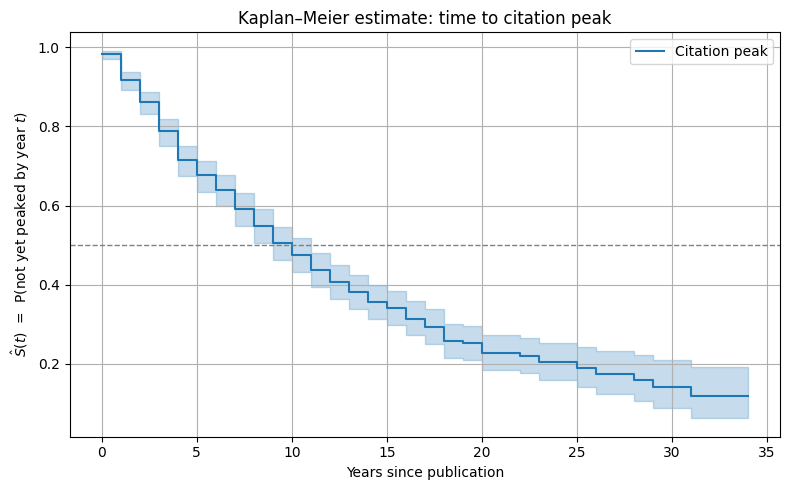

In [3]:
kmf = KaplanMeierFitter()
kmf.fit(durations=df["peak_age"], event_observed=df["peaked"], label="Citation peak")

censoring_rate = 1 - df["peaked"].mean()
print(f"N papers: {len(df)}")
print(f"Censoring rate (not yet peaked): {censoring_rate:.1%}")

ax = kmf.plot_survival_function(ci_show=True)
ax.set_xlabel("Years since publication")
ax.set_ylabel(r"$\hat{S}(t)$  =  P(not yet peaked by year $t$)")
ax.set_title("Kaplan–Meier estimate: time to citation peak")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()


### 1.6 Quantiles of peak age

In [4]:
# --- Convenience: built-in lifelines quantile lookups ---
median_peak_age = kmf.median_survival_time_
ci_median = kmf.confidence_interval_survival_function_

print(f"Median peak age (t_0.5): {median_peak_age:.2f} years")

quantile_levels = [0.25, 0.50, 0.75]
# lifelines wants 1-p as the "percentile" of S(t); .values.ravel() flattens its (n,1) DataFrame output
quantile_ages = kmf.percentile(1 - np.array(quantile_levels)).values.ravel()

quantile_table = pd.DataFrame({
    "quantile (p)": quantile_levels,
    "peak_age (years)": quantile_ages
})
quantile_table


Median peak age (t_0.5): 10.00 years


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(


,quantile (p),peak_age (years)
0,0.25,4.0
1,0.50,10.0
2,0.75,20.0


### 1.7 Is a median peak age of ten years believable?

The estimate in §1.6 says a typical FSR paper does not reach its best citation year until a decade after publication, with an interquartile range of 4–20 years. Ke, Ferrara, Radicchi and Flammini (2015) describe the usual pattern in science as a peak a *few* years out. A ten-year median is far enough from that to need interrogating before it goes in front of the client: either FSR really is slow, or the estimator is measuring something other than ageing.

Three mechanisms could inflate the median, and all three are testable here.

**1. Censoring.** The 39.0% censoring rate is high, and censored observations are exactly the ones that hold $\hat S(t)$ up. But censoring is not spread evenly across the sample: it is almost entirely one kind of paper.

**2. Sparsity.** The median FSR paper has 3 citations in the OpenAlex annual series (4 in the Scopus `cited_by` field). An annual series that sums to 2 or 3 has an argmax determined by where one or two individual citations happened to land, which is closer to a coin flip than to a measurement of ageing. If most of the *observed* peaks come from papers like that, the KM curve is being driven by noise.

**3. Ties.** `np.argmax` returns the *first* maximum, so a paper whose best years are 3 and 14 is recorded as peaking at 3. This one runs the wrong way for our concern: tie-breaking on the first maximum biases peak ages **downward**, so it cannot explain a median that is too late. It is worth quantifying anyway, because it tells us how often the peak year is even well defined.

In [5]:
# Per-paper annual citation vectors (ages 0..current_age, missing years = 0).
# Reused throughout 1.7-1.11, so build it once.
d1 = df.copy()
series = {r.doi: np.array([annual_lookup.get((r.doi, a), 0) for a in range(r.current_age + 1)], float)
          for r in d1.itertuples()}
d1["total_cites"] = d1["doi"].map(lambda k: series[k].sum())
d1["peak_height"] = d1["doi"].map(lambda k: series[k].max())
d1["n_tied_max"]  = d1["doi"].map(lambda k: int((series[k] == series[k].max()).sum()))

n_cens = int((d1["peaked"] == 0).sum())
n_cens_zero = int(((d1["peaked"] == 0) & (d1["total_cites"] == 0)).sum())
print(f"Censored papers: {n_cens} of {len(d1)}")
print(f"  ... of which never cited at all: {n_cens_zero} ({n_cens_zero/n_cens:.0%} of the censoring)")
print(f"  ... median censoring time for never-cited papers: {d1.loc[d1.total_cites==0,'current_age'].median():.0f} years\n")

obs = d1[d1["peaked"] == 1]
print(f"Observed peaks: {len(obs)}. How much data is the argmax actually based on?")
for thr in [1, 2, 5, 10]:
    share = (obs["total_cites"] <= thr).mean()
    print(f"  peaks from papers with <= {thr:2d} lifetime citations : {share:6.1%}")
print(f"  peaks where the annual maximum is a single citation : {(obs['peak_height'] == 1).mean():6.1%}")
print(f"  peaks where two or more years tie at the maximum    : {(obs['n_tied_max'] > 1).mean():6.1%}")

Censored papers: 240 of 616
  ... of which never cited at all: 203 (85% of the censoring)
  ... median censoring time for never-cited papers: 12 years

Observed peaks: 376. How much data is the argmax actually based on?
  peaks from papers with <=  1 lifetime citations :  11.7%
  peaks from papers with <=  2 lifetime citations :  20.5%
  peaks from papers with <=  5 lifetime citations :  41.2%
  peaks from papers with <= 10 lifetime citations :  62.0%
  peaks where the annual maximum is a single citation :  32.4%
  peaks where two or more years tie at the maximum    :  44.1%


Both worries are real. 203 of the 240 censored papers (85% of all the censoring) are papers that have never been cited once; they sit in the risk set for a median of 12 years contributing nothing but delay. And 41.2% of the *observed* peaks come from papers with five or fewer lifetime citations, with a third of them having an annual maximum of exactly one citation. For those papers "the peak year" is just "the year the citation arrived".

So the censoring rate and the sparsity are not separate problems, they are the same problem seen twice: FSR's citation counts are low, which simultaneously produces many never-cited papers (censoring) and many noisy argmaxes (sparsity). The question is whether stripping both out changes the answer. Below we refit KM on progressively better-cited subsets. This is a **robustness check, not a replacement model**: excluding uncited papers would bias the headline estimate, because "not yet peaked" is a legitimate state and those papers belong in the risk set.

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/

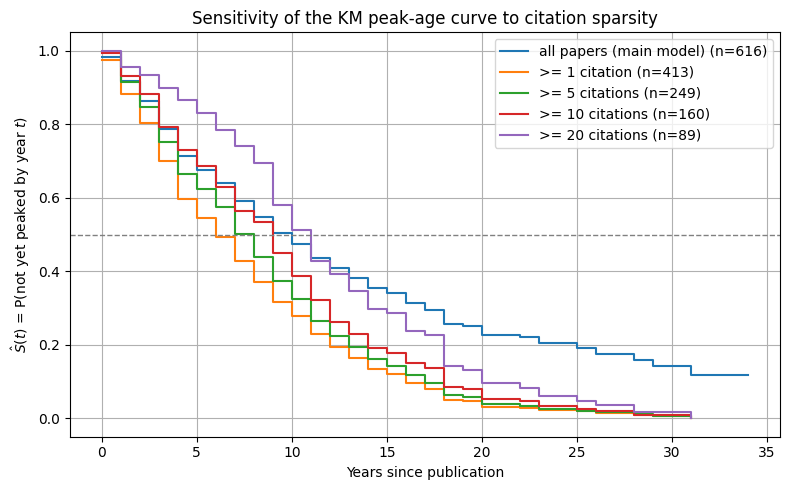

Mature, well-cited subsample (age >= 20 and >= 10 citations): n = 111, censoring 0.9%
  observed peak age: median 10, IQR 6-14.5 years


,subset,N,censored,q25,median,q75
0,all papers (main model),616,39.0%,4.0,10.0,20.0
1,>= 1 citation,413,9.0%,3.0,6.0,11.0
2,>= 5 citations,249,2.8%,4.0,8.0,12.0
3,>= 10 citations,160,3.1%,4.0,9.0,13.0
4,>= 20 citations,89,4.5%,7.0,11.0,16.0


In [6]:
from lifelines import KaplanMeierFitter

def km_quantiles(frame, dur="peak_age", ev="peaked"):
    k = KaplanMeierFitter().fit(frame[dur], frame[ev])
    q25, q50, q75 = k.percentile(1 - np.array([0.25, 0.50, 0.75])).values.ravel()
    return k, q25, q50, q75

rows = []
fig, ax = plt.subplots()
for thr, lab in [(0, "all papers (main model)"), (1, ">= 1 citation"),
                 (5, ">= 5 citations"), (10, ">= 10 citations"), (20, ">= 20 citations")]:
    sub = d1[d1["total_cites"] >= thr]
    k, q25, q50, q75 = km_quantiles(sub)
    rows.append({"subset": lab, "N": len(sub), "censored": 1 - sub["peaked"].mean(),
                 "q25": q25, "median": q50, "q75": q75})
    k.plot_survival_function(ax=ax, ci_show=False, label=f"{lab} (n={len(sub)})")

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Years since publication")
ax.set_ylabel(r"$\hat S(t)$ = P(not yet peaked by year $t$)")
ax.set_title("Sensitivity of the KM peak-age curve to citation sparsity")
plt.tight_layout(); plt.show()

# The cleanest possible subsample: old enough that censoring is nearly absent,
# and cited enough that the annual maximum is not a coin flip.
mature = d1[(d1["current_age"] >= 20) & (d1["total_cites"] >= 10)]
print(f"Mature, well-cited subsample (age >= 20 and >= 10 citations): n = {len(mature)}, "
      f"censoring {1 - mature['peaked'].mean():.1%}")
print("  observed peak age: median {:.0f}, IQR {:.0f}-{:.1f} years".format(
    mature["peak_age"].median(), *np.percentile(mature["peak_age"], [25, 75])))

robust = pd.DataFrame(rows)
robust["censored"] = robust["censored"].map(lambda v: f"{v:.1%}")
robust

The headline number survives. Dropping the never-cited papers collapses the censoring rate from 39.0% to 9.0% and pulls the median down to 6 years, but that subset is still 20% papers with one or two citations. As the citation floor rises and the argmax becomes meaningful, the median climbs back: 8 years at five or more citations, 9 at ten or more, 11 at twenty or more. The cleanest subsample available is the 111 papers that are at least 20 years old *and* have at least 10 citations, where censoring is 0.9% and the annual series has real structure. Their observed median peak age is 10 years, IQR 6–14.5, which lands on the same answer as the full KM fit.

That coincidence is worth stating plainly, because it means the 10-year median is not a censoring artefact and not a sparsity artefact. The honest caveat is about the *spread*, not the centre: the 4–20 year interquartile range in §1.6 is much wider than the 6–14.5 range in the clean subsample, and most of that extra width is the noise contributed by one- and two-citation papers. Report the median with confidence; treat the quartiles as an upper bound on the true dispersion.

One caveat that cannot be tested away. Peak age and observation window are mechanically linked: a paper published in 2015 cannot be recorded as peaking at age 20. KM handles this correctly by censoring, but every quantile beyond about 15 years is estimated off the pre-2010 cohort alone, and should be read as a statement about those cohorts.

### 1.8 What this means for the Academy of Financial Services

**FSR papers peak late, and the estimate is trustworthy.** The Kaplan-Meier median time to citation peak is 10 years. Ke, Ferrara, Radicchi and Flammini (2015) describe the usual pattern in science as a peak a few years after publication, so FSR sits well outside the norm. The two obvious objections both fail. The 39.0% censoring rate looks alarming until you see that 85% of it is never-cited papers, and the sparsity of the annual series is real but does not move the centre: the cleanest subsample available, the 111 papers at least 20 years old with at least 10 citations and a censoring rate of 0.9%, has an observed median peak age of exactly 10 years. The headline figure is not an artefact of censoring and not an artefact of low counts.

**Quote the median, not the quartiles.** The 4 to 20 year interquartile range from the full fit narrows to 6 to 14.5 years in the clean subsample. Most of that extra width is noise contributed by one- and two-citation papers, where "the peak year" really means "the year the citation arrived". Report the centre with confidence and treat the spread as an upper bound on the true dispersion.

**Any editorial intervention will take the better part of a decade to show up in the rankings.** CABS, ABDC and Cabells assessments key off citation windows that are short relative to how FSR papers actually age. A policy change made today first affects papers published in about two years, and on the median estimate those papers will not reach their best citation year until the late 2030s. That is the timescale on which a business case for changing what FSR publishes has to be argued, and it is a concrete reason to resist being judged on two- and three-year citation windows.

**Treat an early citation count as a measure of uptake, not of standing.** With a median peak at 10 years and 39% of the corpus not yet peaked at the data cut-off, a count taken at two or three years is taken long before the typical paper's best year. It tells the editorial team how fast a paper started, which is not the same quantity as how far it will go. Whether early counts nonetheless carry usable signal about eventual totals is a separate question, and Part 2 takes up the related half of the brief: which papers become high hitters, and whether paper-level features visible at submission have anything to say about it.

**What this section cannot tell you.** Peak age and observation window are mechanically linked, so every quantile beyond about 15 years is estimated off the pre-2010 cohorts alone and should be read as a statement about those cohorts rather than about FSR today. The analysis also speaks only to *when* papers peak, not to how high they peak: a paper with three lifetime citations and a paper with 678 contribute equally to the curve. Citation volume is Part 2's subject.


# Question D, part 2: which papers become "high hitters"?

**Question:** Which paper-level factors are associated with higher total citation counts, once we account for older papers having had more time to accrue them?

**Approach:** Negative Binomial regression of total citations on paper-level covariates, with age as an **offset**, so the model describes the citation *rate per year of exposure*. A coefficient means "this shifts citations per year", not "this correlates with being old".

## 2.1 Model

Citation counts are non-negative integers and over-dispersed relative to a Poisson (a few papers get disproportionately many citations, the "high hitters" the question asks about), so Negative Binomial is the standard choice. For paper $i$, let $Y_i$ be total citations, $\text{age}_i$ years since publication, $\mathbf{x}_i$ the paper-level covariates:

$$
Y_i \sim \text{NegBin}(\mu_i, \alpha)
$$

$$
\log(\mu_i) \;=\; \underbrace{\log(\text{age}_i)}_{\text{offset}} \;+\; \beta_0 + \boldsymbol{\beta}^\top \mathbf{x}_i
$$

Equivalently:

$$
\mathbb{E}[Y_i \mid \mathbf{x}_i] \;=\; \text{age}_i \cdot \exp(\beta_0 + \boldsymbol{\beta}^\top \mathbf{x}_i), \qquad \text{Var}(Y_i) = \mu_i + \alpha \mu_i^2
$$

An **offset** has its coefficient fixed at exactly 1 rather than estimated, so expected totals scale linearly with age and everything in $\mathbf{x}_i$ shifts the **citation rate per year**. Each $\exp(\beta_j)$ is an **incidence rate ratio (IRR)**: multiply the yearly rate by $\exp(\beta_j)$ per one-unit increase in $x_j$.

### A check the offset assumption needs before we trust it

Linear accrual conflicts with Part 1's peak-and-decline shape, so we also fit `log(age)` as a **free** covariate and check whether its coefficient comes out near 1. If it does not, the offset version's other coefficients need treating cautiously.

In [7]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import warnings

# statsmodels' NegativeBinomial likelihood throws a benign divide-by-zero warning
# at endog=0 rows during internal log() calls; it doesn't affect the fitted result.
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 2.2 Data & feature engineering

Source: `master_dataset.csv`, filtered to Financial Services Review (it also holds two other journals, see Part 1). None of the covariates exist as ready-made columns:

| Feature | Derivation |
|---|---|
| `n_authors` | count of `;`-separated entries in `authors_id` |
| `n_affiliations` | count of `;`-separated entries in `affiliations` |
| `n_keywords` | count of `;`-separated entries in `author_keywords` (0 if missing) |
| `page_length` | `page_end - page_start` |
| `abstract_length` | word count of `abstract` |
| `pub_year_c` | `year`, mean-centred, controlling for calendar-era effects (see Part 1: the citing literature grew ~7.5x over the sample period, independent of paper age) |
| `age` | years since publication as of the last complete data year |

`document_type` was dropped: every FSR paper here is coded `"Article"`. Rows missing `page_start`/`page_end` (5 papers) or `cited_by` are dropped.

In [8]:
LAST_COMPLETE_YEAR = 2025

master = pd.read_csv("../data/master_dataset.csv")
fsr = master[master["source_title"] == "Financial Services Review"].copy()

fsr["n_authors"]       = fsr["authors_id"].str.split(";").str.len()
fsr["n_affiliations"]  = fsr["affiliations"].fillna("").str.split(";").str.len()
fsr["n_keywords"]      = fsr["author_keywords"].fillna("").apply(lambda s: len(s.split(";")) if s else 0)
fsr["page_length"]     = fsr["page_end"] - fsr["page_start"]
fsr["abstract_length"] = fsr["abstract"].fillna("").str.split().str.len()
fsr["age"]             = LAST_COMPLETE_YEAR - fsr["year"]
fsr["pub_year_c"]      = fsr["year"] - fsr["year"].mean()

fsr = fsr[fsr["age"] > 0].dropna(subset=["cited_by", "page_length"]).copy()
fsr["log_age"] = np.log(fsr["age"])

print(f"document_type unique values: {fsr['document_type'].nunique()}  (dropped -- no variation)")
print(f"Papers in model: {len(fsr)}")
fsr[["n_authors", "n_affiliations", "n_keywords", "page_length",
     "abstract_length", "age", "cited_by"]].describe()


document_type unique values: 1  (dropped -- no variation)
Papers in model: 582


,n_authors,n_affiliations,n_keywords,page_length,abstract_length,age,cited_by
count,582.0000,582.0000,582.0000,582.0000,582.0000,582.0000,582.0000
mean,2.2251,1.7371,3.1392,16.2199,122.6598,16.8144,15.1409
std,0.9198,0.8243,1.9074,5.3468,38.1295,8.9128,43.7554
min,1.0000,1.0000,0.0000,1.0000,3.0000,1.0000,0.0000
25%,2.0000,1.0000,2.0000,13.0000,106.0000,10.0000,2.0000
50%,2.0000,2.0000,3.0000,16.0000,113.0000,17.0000,5.0000
75%,3.0000,2.0000,4.0000,19.0000,128.0000,24.0000,12.0000
max,7.0000,6.0000,11.0000,41.0000,453.0000,34.0000,678.0000


## 2.3 Fit: does the offset assumption hold?

In [9]:
feat_cols = ["n_authors", "n_affiliations", "n_keywords",
             "page_length", "abstract_length", "pub_year_c"]

y = fsr["cited_by"].to_numpy()
X = sm.add_constant(fsr[feat_cols])

# --- free-age model: log(age) as an ordinary covariate, coefficient estimated ---
X_free = sm.add_constant(fsr[["log_age"] + feat_cols])
model_free = sm.NegativeBinomial(y, X_free)
res_free = model_free.fit(disp=0)

age_coef = res_free.params["log_age"]
age_ci = res_free.conf_int().loc["log_age"]
print(f"Estimated log(age) coefficient: {age_coef:.3f}   95% CI [{age_ci[0]:.3f}, {age_ci[1]:.3f}]")
print("Offset assumption (coefficient == 1) is", 
      "reasonable -- 1 falls inside the CI." if age_ci[0] <= 1 <= age_ci[1]
      else "NOT well supported -- 1 falls outside the CI; treat the offset model's coefficients with caution.")


Estimated log(age) coefficient: 1.039   95% CI [0.647, 1.430]
Offset assumption (coefficient == 1) is reasonable -- 1 falls inside the CI.


## 2.4 Main model: age as a fixed offset

In [10]:
offset = np.log(fsr["age"].to_numpy())

model_offset = sm.NegativeBinomial(y, X, offset=offset)
res_offset = model_offset.fit(disp=0)
print(res_offset.summary())


                     NegativeBinomial Regression Results                      
Dep. Variable:                      y   No. Observations:                  582
Model:               NegativeBinomial   Df Residuals:                      575
Method:                           MLE   Df Model:                            6
Date:                Tue, 15 Sep 2026   Pseudo R-squ.:                0.006137
Time:                        12:02:03   Log-Likelihood:                -2008.9
converged:                       True   LL-Null:                       -2021.3
Covariance Type:            nonrobust   LLR p-value:                 0.0003706
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -0.2759      0.342     -0.807      0.420      -0.946       0.394
n_authors           0.2162      0.079      2.732      0.006       0.061       0.371
n_affiliations     -0.1711      

## 2.5 Which variable contributes most?

Raw coefficients are not comparable across variables, since `n_authors` moves in units of one author and `abstract_length` in units of one word. Two complementary views: **incidence rate ratios (IRR)**, $\exp(\beta_j)$, the multiplicative effect of a one-unit change and the natural units to report; and **standardised coefficients**, $\beta_j \times \text{sd}(x_j)$, the effect of a one-*standard-deviation* change, which puts every variable on the same footing for ranking.

In [11]:
irr = np.exp(res_offset.params[feat_cols]).rename("IRR")
pvals = res_offset.pvalues[feat_cols].rename("p-value")
std_effect = (res_offset.params[feat_cols] * fsr[feat_cols].std()).rename("standardized effect")

summary_table = pd.concat([irr, std_effect, pvals], axis=1)
summary_table["abs_std_effect"] = summary_table["standardized effect"].abs()
summary_table = summary_table.sort_values("abs_std_effect", ascending=False).drop(columns="abs_std_effect")
summary_table


,IRR,standardized effect,p-value
page_length,1.0405,0.2124,0.0019
n_authors,1.2413,0.1988,0.0063
abstract_length,0.9952,-0.1817,0.0014
n_affiliations,0.8427,-0.1410,0.0615
pub_year_c,1.0076,0.0678,0.3840
n_keywords,0.9785,-0.0414,0.5294


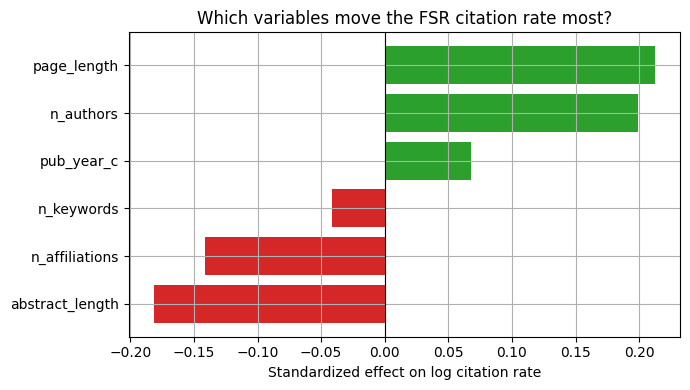

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ordered = summary_table["standardized effect"].sort_values()
colors = ["#d62728" if v < 0 else "#2ca02c" for v in ordered]
ax.barh(ordered.index, ordered.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Standardized effect on log citation rate")
ax.set_title("Which variables move the FSR citation rate most?")
plt.tight_layout()
plt.show()


## 2.6 Is Negative Binomial the right family, and what does the surviving dispersion cost us?

Everything in §2.4 and §2.5 rests on one dispersion parameter:

$$
\text{Var}(Y_i) \;=\; \mu_i + \alpha \mu_i^2, \qquad \hat\alpha = 1.7334
$$

standard error 0.099, nowhere near zero. Two things follow, pulling opposite ways: Poisson would have been badly wrong and the NB is the right correction, but even corrected, the spread around each fitted mean makes that mean a weak description of any individual paper. At $\mu = 15$, roughly the sample mean, Poisson puts the standard deviation at $\sqrt{15} \approx 3.9$ citations and the fitted NB at $\sqrt{15 + 1.7334 \times 15^2} \approx 20$, larger than the mean itself. This conditional distribution is dominated by dispersion, not location.

In [13]:
from scipy import stats
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# --- Poisson on the same design, same offset, for a like-for-like comparison ---
res_pois = sm.Poisson(y, X, offset=offset).fit(disp=0)

alpha = res_offset.params["alpha"]
mu_bar = y.mean()

print("Family comparison (identical covariates and offset)")
print(f"  log-likelihood   Poisson {res_pois.llf:>10.1f}   NB {res_offset.llf:>10.1f}")
print(f"  AIC              Poisson {res_pois.aic:>10.1f}   NB {res_offset.aic:>10.1f}"
      f"   (NB better by {res_pois.aic - res_offset.aic:,.0f})")
print(f"  LR stat for alpha = 0: {2 * (res_offset.llf - res_pois.llf):,.0f} on 1 df")
pearson_disp = (((y - res_pois.predict(X, offset=offset)) ** 2) / res_pois.predict(X, offset=offset)).sum() / (len(y) - X.shape[1])
print(f"  Poisson Pearson dispersion: {pearson_disp:.1f}  (should be ~1 if Poisson held)")

print("\nLargest |z| under each family:")
print(f"  Poisson: page_length z = {res_pois.tvalues['page_length']:.1f}   NB: page_length z = {res_offset.tvalues['page_length']:.1f}")
print(f"  Under Poisson every covariate is 'significant' at p < 0.001, including n_keywords (z = {res_pois.tvalues['n_keywords']:.1f}),")
print(f"  which the NB puts at z = {res_offset.tvalues['n_keywords']:.2f}, p = {res_offset.pvalues['n_keywords']:.2f}.")

print(f"\nWhat alpha = {alpha:.4f} implies:  Var(Y) = mu + {alpha:.4f} * mu^2")
disp_rows = []
for m in [5.0, mu_bar, 50.0]:
    v = m + alpha * m ** 2
    disp_rows.append({"mu": m, "Poisson sd": np.sqrt(m), "NB sd": np.sqrt(v),
                      "sd inflation": np.sqrt(v / m)})
disp = pd.DataFrame(disp_rows).set_index("mu")
print(disp.round(2).to_string())
print(f"\nAt the sample mean mu = {mu_bar:.2f}, the NB conditional sd is {np.sqrt(mu_bar + alpha * mu_bar**2):.1f} citations,")
print(f"i.e. {np.sqrt(mu_bar + alpha*mu_bar**2)/mu_bar:.2f} times the mean itself. Observed marginal sd = {y.std(ddof=1):.2f}.")

Family comparison (identical covariates and offset)
  log-likelihood   Poisson   -10549.6   NB    -2008.9
  AIC              Poisson    21113.3   NB     4033.7   (NB better by 17,080)
  LR stat for alpha = 0: 17,082 on 1 df
  Poisson Pearson dispersion: 76.9  (should be ~1 if Poisson held)

Largest |z| under each family:
  Poisson: page_length z = 26.4   NB: page_length z = 3.1
  Under Poisson every covariate is 'significant' at p < 0.001, including n_keywords (z = -7.2),
  which the NB puts at z = -0.63, p = 0.53.

What alpha = 1.7334 implies:  Var(Y) = mu + 1.7334 * mu^2
         Poisson sd   NB sd  sd inflation
mu                                       
5.0000       2.2400  6.9500        3.1100
15.1409      3.8900 20.3100        5.2200
50.0000      7.0700 66.2100        9.3600

At the sample mean mu = 15.14, the NB conditional sd is 20.3 citations,
i.e. 1.34 times the mean itself. Observed marginal sd = 43.76.


The AIC gap is about 17,000 and the Poisson's Pearson dispersion statistic is 77 where it should be near 1, so the family choice is not close. The damage shows in the $z$-statistics: Poisson calls `n_keywords` significant at $z = -7.2$, a variable the NB correctly reads as noise at $z = -0.63$, $p = 0.53$. Under-dispersion assumptions manufacture precision that is not there.

The NB buys honest standard errors, not a tight conditional distribution, because $\alpha$ is a *constant*: the same 1.7334 applies to a paper expected to earn 2 citations and one expected to earn 45.

### 2.6.1 Where the fitted distribution actually misses

A rootogram compares the implied count distribution, $\hat n_k = \sum_i P(Y_i = k \mid \hat\mu_i, \hat\alpha)$, against the observed frequency at each count $k$, on a square-root scale so small tail frequencies stay visible. Bars hang from the fitted curve: below zero means more papers at that count than expected, above zero fewer.

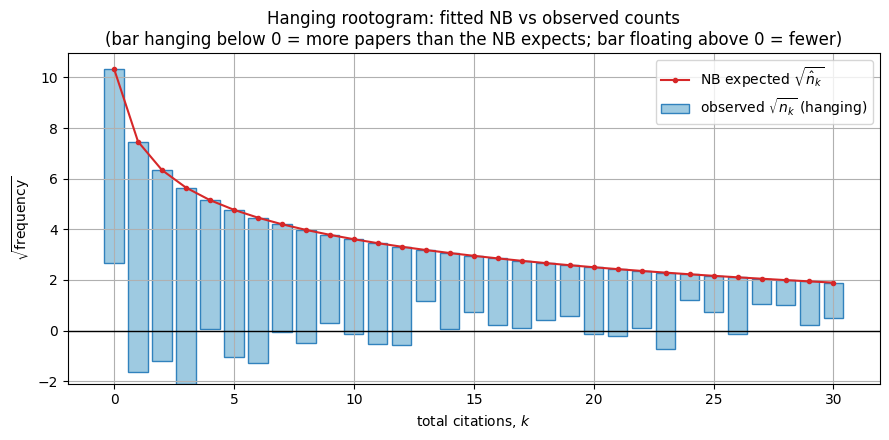

Counts in the body of the distribution:
    observed  NB expected      gap
0         59     106.8000 -47.8000
1         83      55.6000  27.4000
2         57      40.1000  16.9000
3         60      31.9000  28.1000
5         34      22.7000  11.3000
10        14      13.0000   1.0000
20         7       6.3000   0.7000
30         2       3.6000  -1.6000

Zeros: observed 59, NB expects 107. The model manufactures 48 papers with no citations that do not exist,
and is short 27 papers at k = 1 and 28 at k = 3.


In [14]:
# Fitted conditional means, and the NB size/prob parameterisation implied by alpha.
mu_hat = res_offset.predict(X, offset=offset).to_numpy()
size = 1.0 / alpha
prob = size / (size + mu_hat)

# Expected frequency of each count k, summed over papers: sum_i P(Y_i = k | mu_i, alpha).
ks = np.arange(0, 31)
exp_freq = np.array([stats.nbinom.pmf(k, size, prob).sum() for k in ks])
obs_freq = np.array([(y == k).sum() for k in ks])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(ks, np.sqrt(obs_freq), bottom=np.sqrt(exp_freq) - np.sqrt(obs_freq),
       width=0.8, color="#9ecae1", edgecolor="#3182bd", label=r"observed $\sqrt{n_k}$ (hanging)")
ax.plot(ks, np.sqrt(exp_freq), color="#d62728", marker="o", ms=3, lw=1.5,
        label=r"NB expected $\sqrt{\hat{n}_k}$")
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("total citations, $k$")
ax.set_ylabel(r"$\sqrt{\text{frequency}}$")
ax.set_title("Hanging rootogram: fitted NB vs observed counts\n(bar hanging below 0 = more papers than the NB expects; bar floating above 0 = fewer)")
ax.legend()
plt.tight_layout(); plt.show()

comp = pd.DataFrame({"observed": obs_freq, "NB expected": exp_freq}, index=ks).loc[[0,1,2,3,5,10,20,30]]
comp["gap"] = comp["observed"] - comp["NB expected"]
print("Counts in the body of the distribution:")
print(comp.round(1).to_string())
print(f"\nZeros: observed {obs_freq[0]}, NB expects {exp_freq[0]:.0f}. The model manufactures "
      f"{exp_freq[0] - obs_freq[0]:.0f} papers with no citations that do not exist,")
print(f"and is short {obs_freq[1] - exp_freq[1]:.0f} papers at k = 1 and {obs_freq[3] - exp_freq[3]:.0f} at k = 3.")

The misfit is systematic, not scatter. The model expects 107 uncited papers against 59 observed, inventing 48 zeros, and pays for them by being short 27 papers at $k=1$ and 28 at $k=3$. The real distribution has a denser, more compact body than a Negative Binomial with this $\alpha$ can produce, and the same single $\alpha$ stretching the body has to do the work in the tail.

### 2.6.2 What the fitted model thinks FSR's tail looks like

Generate synthetic journals and ask whether they look like FSR: 2,000 replicate datasets of 582 papers, each paper $i$ drawn from $\text{NegBin}(\hat\mu_i, \hat\alpha)$, compared against the observed upper tail.

In [15]:
rng = np.random.default_rng(42)
B = 2000
sim = rng.negative_binomial(size, prob, size=(B, len(mu_hat)))   # B synthetic FSR journals

tail_rows = []
for c in [26, 50, 100, 200]:
    cnt = (sim >= c).sum(axis=1)
    tail_rows.append({"threshold": f">= {c}", "observed": int((y >= c).sum()),
                      "NB expected": cnt.mean(),
                      "NB 95% interval": f"[{np.percentile(cnt, 2.5):.0f}, {np.percentile(cnt, 97.5):.0f}]"})
tail = pd.DataFrame(tail_rows).set_index("threshold")
print("Papers above each citation threshold: real FSR vs 2,000 simulated FSRs from the fitted NB")
print(tail.round(1).to_string())

sim_max = sim.max(axis=1)
sim_sd = sim.std(axis=1, ddof=1)
print(f"\nMost-cited paper:  observed {y.max()}, "
      f"NB simulated median {np.median(sim_max):.0f}, 95% interval [{np.percentile(sim_max, 2.5):.0f}, {np.percentile(sim_max, 97.5):.0f}]")
print(f"  P(a simulated FSR produces a paper with >= {y.max()} citations) = {(sim_max >= y.max()).mean():.4f}  "
      f"(0 of {B} replications)")
print(f"\nMarginal sd:       observed {y.std(ddof=1):.1f}, NB simulated median {np.median(sim_sd):.1f} "
      f"[{np.percentile(sim_sd, 2.5):.1f}, {np.percentile(sim_sd, 97.5):.1f}]")
print(f"90th percentile:   observed {np.percentile(y, 90):.0f}, NB simulated median {np.median(np.percentile(sim, 90, axis=1)):.0f}")

Papers above each citation threshold: real FSR vs 2,000 simulated FSRs from the fitted NB
           observed  NB expected NB 95% interval
threshold                                       
>= 26            63     104.7000       [88, 121]
>= 50            33      41.0000        [30, 53]
>= 100           18       8.2000         [3, 14]
>= 200            6       0.6000          [0, 3]

Most-cited paper:  observed 678, NB simulated median 196, 95% interval [129, 365]
  P(a simulated FSR produces a paper with >= 678 citations) = 0.0000  (0 of 2000 replications)

Marginal sd:       observed 43.8, NB simulated median 23.2 [19.4, 28.6]
90th percentile:   observed 26, NB simulated median 40


**Moderate tail, over-predicted.** The NB expects 105 papers at 26 or more citations, 95% interval [88, 121]; FSR has 63, well outside it, so this is misfit rather than sampling noise. The model's own 90th percentile is 40 citations where FSR's is 26.

**Extreme tail, under-predicted.** It expects 8 papers at 100 or more, interval [3, 14], against FSR's 18; at 200 or more, 0.6 against 6. Across 2,000 simulated journals not one produced a paper matching FSR's most-cited article at 678 citations: the simulated maximum has a median of 196 and a 97.5th percentile of 365. The paper that most defines "high hitter" at FSR is an event the model treats as essentially impossible.

Fitted marginal standard deviation: 23, observed 43.8. The NB has not absorbed FSR's dispersion, it has redistributed it, spreading too much probability over 26 to 60 and not nearly enough past 100. One $\alpha$ cannot make the body compact and the tail heavy at once.

## 2.7 What a pseudo R² of 0.0061 says, and what it does not

McFadden's pseudo $R^2$ is

$$
R^2_{\text{McF}} \;=\; 1 - \frac{\log L_{\text{full}}}{\log L_{\text{null}}}
$$

a ratio of log-likelihoods, not a proportion of variance, so it is not "0.6% of variation explained". McFadden himself noted that 0.2 to 0.4 already represents excellent fit for discrete models.

It does mean six covariates moved the log-likelihood from $-2021.3$ to $-2008.9$, a gain of 12.4 units, and that gain is real: the likelihood-ratio test gives $p = 0.00037$. Significance and explanatory reach separate here about as far as they can. What matters is how far the fitted values can travel.

In [16]:
# The covariate-driven part of the fitted value: exp(b0 + b'x), i.e. citations per year with age divided out.
rate_hat = np.exp(X.to_numpy() @ res_offset.params.drop("alpha").to_numpy())

print(f"McFadden pseudo R^2 = 1 - LL_full/LL_null = 1 - ({res_offset.llf:.1f})/({res_offset.llnull:.1f}) "
      f"= {1 - res_offset.llf / res_offset.llnull:.6f}")
print(f"LR statistic {res_offset.llr:.1f} on {int(res_offset.df_model)} df, p = {res_offset.llr_pvalue:.5f}  "
      "-> the covariates are jointly significant.\n")

print("Spread of what the model predicts vs spread of what actually happened:")
print(f"  fitted mu_i:        min {mu_hat.min():.2f}   max {mu_hat.max():.2f}   range {mu_hat.max() - mu_hat.min():.1f}")
print(f"  observed citations: min {y.min():.0f}      max {y.max():.0f}    range {y.max() - y.min():.0f}")
print(f"  fitted range / observed range = {(mu_hat.max() - mu_hat.min()) / (y.max() - y.min()):.3f}")
print(f"  sd(fitted) / sd(observed)     = {mu_hat.std(ddof=1) / y.std(ddof=1):.3f}   "
      f"(var ratio {mu_hat.var(ddof=1) / y.var(ddof=1):.3f})")

print(f"\n  Pearson corr(fitted, observed)  = {np.corrcoef(mu_hat, y)[0, 1]:.3f}")
print(f"  Spearman corr(fitted, observed) = {pd.Series(mu_hat).corr(pd.Series(y), method='spearman'):.3f}")

print("\nHow far can the covariates alone move the citation RATE (age divided out)?")
print(f"  full range of exp(b0 + b'x): {rate_hat.min():.2f} to {rate_hat.max():.2f} cites/yr "
      f"= a factor of {rate_hat.max() / rate_hat.min():.1f} across the whole covariate space")
print(f"  5th to 95th percentile:      {np.percentile(rate_hat, 5):.2f} to {np.percentile(rate_hat, 95):.2f} "
      f"= a factor of {np.percentile(rate_hat, 95) / np.percentile(rate_hat, 5):.2f}")
print(f"  interquartile:               factor of {np.percentile(rate_hat, 75) / np.percentile(rate_hat, 25):.2f}")
print(f"\n  Observed citations span 0 to {y.max():.0f}, a range the covariates cannot begin to generate.")

McFadden pseudo R^2 = 1 - LL_full/LL_null = 1 - (-2008.9)/(-2021.3) = 0.006137
LR statistic 24.8 on 6 df, p = 0.00037  -> the covariates are jointly significant.

Spread of what the model predicts vs spread of what actually happened:
  fitted mu_i:        min 0.56   max 48.37   range 47.8
  observed citations: min 0      max 678    range 678
  fitted range / observed range = 0.071
  sd(fitted) / sd(observed)     = 0.177   (var ratio 0.031)

  Pearson corr(fitted, observed)  = 0.220
  Spearman corr(fitted, observed) = 0.347

How far can the covariates alone move the citation RATE (age divided out)?
  full range of exp(b0 + b'x): 0.34 to 2.74 cites/yr = a factor of 8.0 across the whole covariate space
  5th to 95th percentile:      0.58 to 1.54 = a factor of 2.65
  interquartile:               factor of 1.44

  Observed citations span 0 to 678, a range the covariates cannot begin to generate.


Three numbers carry this. Fitted means span 0.56 to 48.4 citations against data spanning 0 to 678: 7% of the observed range. Net of age, the covariates move the predicted citation *rate* by a factor of 2.65 between the 5th and 95th percentile of the covariate space, 1.44 across the interquartile range, and 8 even at the extremes of every covariate at once (0.34 to 2.74 citations per year). And fitted values correlate with the outcome at $r = 0.22$, so $\text{var}(\hat\mu)$ is 3% of $\text{var}(y)$.

So §2.4 honestly summarised: `n_authors`, `page_length` and `abstract_length` genuinely shift the expected citation rate, the evidence is sound, and the shift is roughly a doubling across the whole realistic range of paper characteristics while actual counts vary by three orders of magnitude. The covariates are real and small, and a richer mean model would not change that, because the problem is not the estimator.

## 2.8 Why a mean-based model structurally cannot answer a tail question

Suppose the NB fitted perfectly. It would still be the wrong tool. It pairs a single conditional mean $\mu_i$ with an $\alpha$ that does not depend on $\mathbf{x}_i$, so the *shape* of the conditional distribution is identical for every paper. Covariates slide the distribution along the count axis; they cannot make it more skewed for one paper than another, widen its spread independently of its centre, or move its 90th percentile except by moving its mean. Every conditional quantile is a deterministic function of $\mu_i$ alone.

"Which papers become high hitters" asks about $Q_{0.9}(Y \mid \mathbf{x})$, which under the NB moves only in lockstep with the mean at a ratio fixed by $\alpha$. If the real tail does not behave that way, no quality of estimation will help. That is testable.

,n,fitted_mu,obs_mean,obs_median,obs_q90,obs_max,obs q90/mean,NB-implied q90/mean
mu_decile,,,,,,,,
1,59,2.2500,2.5800,1.0000,6.0000,18,2.3300,2.6600
2,58,6.2000,3.1700,2.0000,8.3000,20,2.6200,2.7400
3,58,9.2900,11.4700,5.0000,23.2000,149,2.0200,2.6900
4,58,11.6200,15.3300,5.5000,23.3000,174,1.5200,2.6700
5,58,13.6200,10.9700,5.5000,16.6000,193,1.5100,2.6400
6,58,15.8200,7.8600,4.0000,15.6000,100,1.9800,2.6500
7,58,17.6200,17.4300,8.0000,36.1000,171,2.0700,2.6700
8,58,19.5600,20.6200,6.0000,34.2000,346,1.6600,2.6600
9,58,22.0100,29.3300,8.0000,62.2000,334,2.1200,2.6400



Observed  q90/mean across deciles: 1.51 to 2.62  (varies by a factor of 1.73)
NB-implied q90/mean across deciles: 2.64 to 2.74  (varies by a factor of 1.04)

The NB is locked into a near-constant tail-to-mean ratio because a single alpha fixes the shape
for every paper. The data will not hold still at that ratio.

Deciles 3-5 have fitted means of 9.3-13.6 citations, yet contain papers with
149, 174 and 193 citations. For a paper with mu = 11.6, the fitted NB puts its own 90th
percentile at 31 citations and its 99.9th at 117.

Across deciles 3-10 the fitted mean rises 3.1x (9.3 -> 29.1). Over the same span the observed
  median  moves 4.0 -> 8.0 (a 2.0x band, and non-monotone),
  mean    moves 7.9 -> 32.6,
  90th pct moves 15.6 -> 62.2.
Almost all of the ordering the fitted mean achieves is ordering of the tail, not of the typical paper.


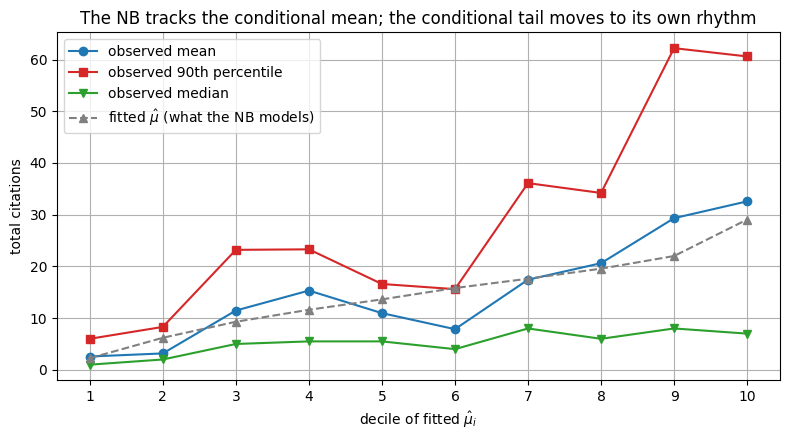

In [17]:
fsr["nb_fitted"] = mu_hat
fsr["mu_decile"] = pd.qcut(fsr["nb_fitted"], 10, labels=False) + 1

bins = fsr.groupby("mu_decile").agg(
    n=("cited_by", "size"),
    fitted_mu=("nb_fitted", "mean"),
    obs_mean=("cited_by", "mean"),
    obs_median=("cited_by", "median"),
    obs_q90=("cited_by", lambda s: s.quantile(0.90)),
    obs_max=("cited_by", "max"),
)
bins["obs q90/mean"] = bins["obs_q90"] / bins["obs_mean"]
# What the fitted NB says that ratio MUST be, given each bin's mean and the single shared alpha.
bins["NB-implied q90/mean"] = [stats.nbinom.ppf(0.90, size, size / (size + m)) / m for m in bins["fitted_mu"]]
display(bins.round(2))

lo, hi = bins["obs q90/mean"].min(), bins["obs q90/mean"].max()
nlo, nhi = bins["NB-implied q90/mean"].min(), bins["NB-implied q90/mean"].max()
print(f"\nObserved  q90/mean across deciles: {lo:.2f} to {hi:.2f}  (varies by a factor of {hi/lo:.2f})")
print(f"NB-implied q90/mean across deciles: {nlo:.2f} to {nhi:.2f}  (varies by a factor of {nhi/nlo:.2f})")
print("\nThe NB is locked into a near-constant tail-to-mean ratio because a single alpha fixes the shape")
print("for every paper. The data will not hold still at that ratio.")
print(f"\nDeciles 3-5 have fitted means of {bins.loc[3,'fitted_mu']:.1f}-{bins.loc[5,'fitted_mu']:.1f} citations, yet contain papers with")
print(f"{bins.loc[3,'obs_max']:.0f}, {bins.loc[4,'obs_max']:.0f} and {bins.loc[5,'obs_max']:.0f} citations. For a paper with mu = {bins.loc[4,'fitted_mu']:.1f}, the fitted NB puts its own 90th")
print(f"percentile at {stats.nbinom.ppf(0.90, size, size/(size+bins.loc[4,'fitted_mu'])):.0f} citations and its 99.9th at "
      f"{stats.nbinom.ppf(0.999, size, size/(size+bins.loc[4,'fitted_mu'])):.0f}.")

top = bins.loc[3:, ["obs_mean", "obs_median", "obs_q90"]]
print(f"\nAcross deciles 3-10 the fitted mean rises {bins.loc[10,'fitted_mu']/bins.loc[3,'fitted_mu']:.1f}x "
      f"({bins.loc[3,'fitted_mu']:.1f} -> {bins.loc[10,'fitted_mu']:.1f}). Over the same span the observed")
print(f"  median  moves {top['obs_median'].min():.1f} -> {top['obs_median'].max():.1f} (a {top['obs_median'].max()/top['obs_median'].min():.1f}x band, and non-monotone),")
print(f"  mean    moves {top['obs_mean'].min():.1f} -> {top['obs_mean'].max():.1f},")
print(f"  90th pct moves {top['obs_q90'].min():.1f} -> {top['obs_q90'].max():.1f}.")
print("Almost all of the ordering the fitted mean achieves is ordering of the tail, not of the typical paper.")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(bins.index, bins["obs_mean"], "o-", color="#1f77b4", label="observed mean")
ax.plot(bins.index, bins["obs_q90"], "s-", color="#d62728", label="observed 90th percentile")
ax.plot(bins.index, bins["obs_median"], "v-", color="#2ca02c", label="observed median")
ax.plot(bins.index, bins["fitted_mu"], "^--", color="gray", label=r"fitted $\hat\mu$ (what the NB models)")
ax.set_xlabel(r"decile of fitted $\hat\mu_i$")
ax.set_ylabel("total citations")
ax.set_title("The NB tracks the conditional mean; the conditional tail moves to its own rhythm")
ax.set_xticks(bins.index)
ax.legend()
plt.tight_layout(); plt.show()

The last two columns are the test. With $\alpha$ fixed at 1.7334 the NB insists a paper's 90th-percentile-to-mean ratio sits between 2.64 and 2.74 whichever decile it belongs to, a band of 4%. The data puts it between 1.51 and 2.62, a factor of 1.73, unrelated to the fitted mean.

Worse, across deciles 3 to 10 the fitted mean rises 3.1-fold (9.3 to 29.1) while the observed median wanders non-monotonically between 4 and 8 and the observed 90th percentile climbs from 15.6 to 62.2. Almost everything the fitted mean orders is tail behaviour; for a typical FSR paper, whichever decile of $\hat\mu$ it lands in, the median outcome is about five citations.

Nor does the mean say how extreme the extremes can be. Deciles 3, 4 and 5 (fitted means 9.3, 11.6, 13.6 citations) contain papers cited 149, 174 and 193 times. At $\mu = 11.6$ the fitted NB puts the 90th percentile at 31 citations and the 99.9th at 117, making a 174-citation outcome a one-in-several-thousand event. There are three, in three adjacent deciles.

### 2.8.1 The high-hitter label, and what the mean model recovers

Define a high hitter as a paper in the top 10% by total citations: a fixed cutoff on the raw count, so unlike the NB's rate-based coefficients it does not adjust for age (§2.9). Threshold the §2.4 fitted $\hat\mu_i$ at its own 90th percentile to match the 10% base rate and see which papers it picks.

In [18]:
threshold_actual = fsr["cited_by"].quantile(0.90)
fsr["high_hitter"] = (fsr["cited_by"] >= threshold_actual).astype(int)
n_high, base_rate = fsr["high_hitter"].sum(), fsr["high_hitter"].mean()
print(f"High-hitter cutoff: >= {threshold_actual:.0f} citations ({n_high} of {len(fsr)} papers, {base_rate:.1%})")

nb_threshold = fsr["nb_fitted"].quantile(0.90)
fsr["nb_pred_high"] = (fsr["nb_fitted"] >= nb_threshold).astype(int)

cm_nb = confusion_matrix(fsr["high_hitter"], fsr["nb_pred_high"])
tn, fp, fn, tp = cm_nb.ravel()
print("\nConfusion matrix (rows = actual, cols = predicted):")
print(pd.DataFrame(cm_nb, index=["actual: not high hitter", "actual: high hitter"],
                   columns=["pred: not high hitter", "pred: high hitter"]))
print(f"\nTP={tp}  FP={fp}  TN={tn}  FN={fn}")
print(classification_report(fsr["high_hitter"], fsr["nb_pred_high"], digits=2))

auc_nb = roc_auc_score(fsr["high_hitter"], fsr["nb_fitted"])
print(f"AUC (threshold-free): {auc_nb:.3f}")

# What would flagging papers at random achieve? The benchmark accuracy = 0.84 hides.
n_flagged = tp + fp
expected_tp = n_flagged * base_rate
print(f"\nBenchmark: the rule flags {n_flagged} papers and catches {tp} true high hitters.")
print(f"  Flagging {n_flagged} papers at random would catch {expected_tp:.1f} on average.")
print(f"  Lift over random = {tp / expected_tp:.2f}x.")
print(f"  P(catching >= {tp} by chance alone) = {stats.hypergeom.sf(tp - 1, len(fsr), n_high, n_flagged):.4f} (hypergeometric).")
print(f"  Accuracy of {(tp + tn) / len(fsr):.2f} is not informative here: always predicting 'not a high hitter'")
print(f"  scores {1 - base_rate:.2f} while catching none of the {n_high}.")

High-hitter cutoff: >= 26 citations (63 of 582 papers, 10.8%)

Confusion matrix (rows = actual, cols = predicted):
                         pred: not high hitter  pred: high hitter
actual: not high hitter                    473                 46
actual: high hitter                         50                 13

TP=13  FP=46  TN=473  FN=50
              precision    recall  f1-score   support

           0       0.90      0.91      0.91       519
           1       0.22      0.21      0.21        63

    accuracy                           0.84       582
   macro avg       0.56      0.56      0.56       582
weighted avg       0.83      0.84      0.83       582

AUC (threshold-free): 0.712

Benchmark: the rule flags 59 papers and catches 13 true high hitters.
  Flagging 59 papers at random would catch 6.4 on average.
  Lift over random = 2.04x.
  P(catching >= 13 by chance alone) = 0.0062 (hypergeometric).
  Accuracy of 0.84 is not informative here: always predicting 'not a high hitter'


Read the confusion matrix against the right benchmark. The rule flags 59 papers and catches 13 of the 63 real high hitters where flagging 59 at random would catch 6.4: signal, at a lift of 2.04 times chance, hypergeometric $p = 0.0062$. It is also not usable. An editor working this list reads 59 papers to find 13, having missed 50, and would have found 6 of those 13 by drawing names from a hat.

Ignore the accuracy of 0.84: a rule that flags nothing scores 0.89 and finds no high hitters at all. The threshold-free AUC of 0.712 is the honest summary.

## 2.9 The raw high-hitter label is partly just a label for "old"

§2.8.1 has a mismatch built into it. The NB is rate-based, with age in the offset and coefficients in citations per year; the high-hitter label is count-based and not age-adjusted. A 30-year-old paper needs 0.87 citations a year to clear 26 and a 5-year-old paper needs 5.2, so the label gets easier the longer a paper has existed.

In [19]:
hh, oth = fsr.loc[fsr["high_hitter"] == 1, "age"], fsr.loc[fsr["high_hitter"] == 0, "age"]
print(f"Age of the {len(hh)} high hitters:  mean {hh.mean():.1f}, median {hh.median():.0f} years")
print(f"Age of the other {len(oth)} papers:  mean {oth.mean():.1f}, median {oth.median():.0f} years")
print(f"Mann-Whitney U test of equal age distributions: p = {stats.mannwhitneyu(hh, oth).pvalue:.2e}")

fsr["age_tertile"] = pd.qcut(fsr["age"], 3, labels=["youngest", "middle", "oldest"])
tert = fsr.groupby("age_tertile", observed=True).agg(
    n=("age", "size"), age_range=("age", lambda s: f"{s.min():.0f}-{s.max():.0f} yrs"),
    high_hitters=("high_hitter", "sum"), pct_high=("high_hitter", lambda s: 100 * s.mean()))
print("\nWhere the high hitters live:")
print(tert.round(1).to_string())
print(f"\nA paper in the oldest tertile is {tert.loc['oldest','pct_high'] / tert.loc['youngest','pct_high']:.1f}x "
      "as likely to be labelled a high hitter as one in the youngest.")

# --- Direct logistic model on the raw label, log_age as a control ---
X_logit = sm.add_constant(fsr[["log_age"] + feat_cols])
logit_direct = sm.Logit(fsr["high_hitter"], X_logit).fit(disp=0)
print(logit_direct.summary())

fsr["logit_pred"] = logit_direct.predict(X_logit)
auc_direct = roc_auc_score(fsr["high_hitter"], fsr["logit_pred"])
print(f"\nAUC, direct logistic model: {auc_direct:.3f}    AUC, NB fitted mean: {auc_nb:.3f}")

b_age = logit_direct.params["log_age"]
print(f"\nlog_age coefficient = {b_age:.3f}. Because age enters as a log, this is an elasticity on the odds:")
print(f"  doubling a paper's age multiplies its odds of being a high hitter by 2^{b_age:.2f} = {2 ** b_age:.0f}")
print(f"  a 25-year-old paper vs a 5-year-old one: odds ratio (25/5)^{b_age:.2f} = {5 ** b_age:,.0f}")
print(f"  by comparison, one extra author multiplies the odds by only {np.exp(logit_direct.params['n_authors']):.2f}")

Age of the 63 high hitters:  mean 21.2, median 22 years
Age of the other 519 papers:  mean 16.3, median 16 years
Mann-Whitney U test of equal age distributions: p = 2.55e-05

Where the high hitters live:
               n  age_range  high_hitters  pct_high
age_tertile                                        
youngest     203   1-12 yrs             8    3.9000
middle       193  13-22 yrs            27   14.0000
oldest       186  23-34 yrs            28   15.1000

A paper in the oldest tertile is 3.8x as likely to be labelled a high hitter as one in the youngest.
                           Logit Regression Results                           
Dep. Variable:            high_hitter   No. Observations:                  582
Model:                          Logit   Df Residuals:                      574
Method:                           MLE   Df Model:                            7
Date:                Tue, 15 Sep 2026   Pseudo R-squ.:                  0.1037
Time:                        12:02:03  

High hitters average 21.2 years old against 16.3 for everyone else, $p = 2.6 \times 10^{-5}$, and only 8 of the 203 papers in the youngest tertile carry the label, 3.9%, against 15.1% in the oldest.

The logistic model makes it explicit. The `log_age` coefficient of 5.17 is an elasticity on the odds: doubling age multiplies the odds of the label by $2^{5.17} = 36$, so a 25-year-old paper has roughly 4,100 times the odds of a 5-year-old one, while an extra author, the strongest content effect, multiplies them by 1.54. The strongest predictor of the raw label is being old, and it is not close.

Question D asks whether breakout papers can be **spotted early**, and a label whose dominant driver is age is close to unanswerable in those terms: the variable doing the predicting is the one thing a new paper cannot have.

### 2.9.1 An age-adjusted alternative label

Define the top decile on citations per year instead. If the two definitions largely agreed, the age problem would be cosmetic.

In [20]:
fsr["cites_per_year"] = fsr["cited_by"] / fsr["age"]
rate_cut = fsr["cites_per_year"].quantile(0.90)
fsr["high_rate"] = (fsr["cites_per_year"] >= rate_cut).astype(int)
print(f"Age-adjusted label: top 10% by citations per year, cutoff >= {rate_cut:.2f} cites/yr "
      f"({fsr['high_rate'].sum()} papers, {fsr['high_rate'].mean():.1%})")

both = ((fsr["high_hitter"] == 1) & (fsr["high_rate"] == 1)).sum()
raw_only = ((fsr["high_hitter"] == 1) & (fsr["high_rate"] == 0)).sum()
rate_only = ((fsr["high_hitter"] == 0) & (fsr["high_rate"] == 1)).sum()
print(f"\nOverlap: {both} papers carry both labels.")
print(f"  {raw_only} of the {fsr['high_hitter'].sum()} raw high hitters are NOT in the top 10% by rate.")
print(f"  {rate_only} papers in the top 10% by rate are NOT raw high hitters.")
print(f"  Jaccard agreement = {both / ((fsr['high_hitter'] | fsr['high_rate']).sum()):.3f}")

cols = ["title", "year", "age", "cited_by", "cites_per_year"]
print("\nRaw high hitters the rate label rejects (old, slow accumulation):")
print(fsr[(fsr["high_hitter"] == 1) & (fsr["high_rate"] == 0)].nlargest(3, "cited_by")[cols].to_string(index=False))
print("\nTop-10%-by-rate papers the raw label misses (young, fast accumulation):")
print(fsr[(fsr["high_hitter"] == 0) & (fsr["high_rate"] == 1)].nlargest(3, "cites_per_year")[cols].to_string(index=False))

print("\nHigh hitters by age tertile under each label definition:")
print(fsr.groupby("age_tertile", observed=True).agg(
    n=("age", "size"),
    pct_raw_label=("high_hitter", lambda s: 100 * s.mean()),
    pct_rate_label=("high_rate", lambda s: 100 * s.mean())).round(1).to_string())

Age-adjusted label: top 10% by citations per year, cutoff >= 2.00 cites/yr (61 papers, 10.5%)

Overlap: 39 papers carry both labels.
  24 of the 63 raw high hitters are NOT in the top 10% by rate.
  22 papers in the top 10% by rate are NOT raw high hitters.
  Jaccard agreement = 0.459

Raw high hitters the rate label rejects (old, slow accumulation):
                                                                                  title  year  age  cited_by  cites_per_year
Household insolvency: A review of household debt repayment, delinquency, and bankruptcy  1995   30        58          1.9333
                  Financial Inhibition, Financial Activation, and Saving for Retirement  2003   22        42          1.9091
                                        Asset allocation, life expectancy and shortfall  1994   31        42          1.3548

Top-10%-by-rate papers the raw label misses (young, fast accumulation):
                                                                  title  y

They do not agree. Only 39 papers carry both labels, a Jaccard agreement of 0.46: twenty-four of the 63 raw high hitters fall out and 22 different papers come in.

The papers name the problem. "Household insolvency: A review of household debt repayment, delinquency, and bankruptcy" (1995) has 58 citations and clears the raw cutoff comfortably, but that is 1.93 citations a year over thirty years. "Investment literacy, overconfidence and cryptocurrency investment" (2023) has 18 citations in two years, 9.0 per year, nearly five times the pace, and the raw label does not see it. If AFS wants to know what is working now, §2.8.1 discards the more informative paper.

The tertiles confirm a complete reversal: 15.1% of the oldest tertile against 3.9% of the youngest under the raw label, flipping to 8.1% and 14.8% under the rate label.

### 2.9.2 So how much of that AUC was ever about the paper?

The logistic model's AUC of 0.723 against the NB's 0.712 might look like a classifier fixes something. It does not. One trap before stripping age out: `pub_year_c` is `year - mean(year)` and `age` is `2025 - year`, perfectly negatively collinear, so dropping `log_age` while keeping `pub_year_c` changes the functional form rather than removing age. A genuinely age-free model has to drop both.

In [21]:
# CAUTION: pub_year_c = year - mean(year) and age = 2025 - year, so pub_year_c is an exact
# negative linear transform of age. Simply dropping log_age does NOT remove age from the model.
print(f"corr(age, pub_year_c) = {np.corrcoef(fsr['age'], fsr['pub_year_c'])[0,1]:.4f}  "
      "<- perfectly collinear; pub_year_c IS age, rescaled.")

content_cols = ["n_authors", "n_affiliations", "n_keywords", "page_length", "abstract_length"]

def fit_auc(cols, label):
    Xc = sm.add_constant(fsr[cols])
    m = sm.Logit(fsr[label], Xc).fit(disp=0)
    return roc_auc_score(fsr[label], m.predict(Xc)), m

ladder = []
for cols, name in [(["log_age"] + feat_cols, "all covariates + log_age"),
                   (feat_cols,               "drop log_age, keep pub_year_c"),
                   (["log_age"],             "age alone"),
                   (content_cols,            "content only (no age, no year)")]:
    a, _ = fit_auc(cols, "high_hitter")
    ladder.append({"predictors": name, "AUC on raw label": a})
ladder = pd.DataFrame(ladder).set_index("predictors")
ladder["AUC on rate label"] = [fit_auc(c, "high_rate")[0] for c, _ in
    [(["log_age"] + feat_cols, 0), (feat_cols, 0), (["log_age"], 0), (content_cols, 0)]]
display(ladder.round(3))

print(f"\nAge alone reaches AUC {ladder.loc['age alone','AUC on raw label']:.3f} on the raw label.")
print(f"All five content covariates together, with age and calendar year fully removed, reach "
      f"{ladder.loc['content only (no age, no year)','AUC on raw label']:.3f}:")
print("less than age by itself. Adding age back buys only "
      f"{ladder.loc['all covariates + log_age','AUC on raw label'] - ladder.loc['content only (no age, no year)','AUC on raw label']:.3f} AUC.")

_, m_rate = fit_auc(["log_age"] + feat_cols, "high_rate")
print(f"\nOn the age-adjusted label the log_age coefficient flips sign: "
      f"{m_rate.params['log_age']:.3f} (p = {m_rate.pvalues['log_age']:.3f}),")
print("i.e. once the target is a rate, OLDER papers are LESS likely to be in the top decile,")
print("which is what Part 1's peak-and-decline trajectory predicts.")
print(f"n_authors survives as the only near-significant content term: coef "
      f"{m_rate.params['n_authors']:.3f}, p = {m_rate.pvalues['n_authors']:.3f}.")

corr(age, pub_year_c) = -1.0000  <- perfectly collinear; pub_year_c IS age, rescaled.


,AUC on raw label,AUC on rate label
predictors,,
all covariates + log_age,0.7230,0.6520
"drop log_age, keep pub_year_c",0.6990,0.6340
age alone,0.6620,0.5930
"content only (no age, no year)",0.6520,0.6220



Age alone reaches AUC 0.662 on the raw label.
All five content covariates together, with age and calendar year fully removed, reach 0.652:
less than age by itself. Adding age back buys only 0.070 AUC.

On the age-adjusted label the log_age coefficient flips sign: -0.818 (p = 0.031),
i.e. once the target is a rate, OLDER papers are LESS likely to be in the top decile,
which is what Part 1's peak-and-decline trajectory predicts.
n_authors survives as the only near-significant content term: coef 0.318, p = 0.062.


The numbers are worse than the headline AUCs suggest.

Age alone scores 0.662 on the raw label. All five content covariates together, with age and calendar year removed, score 0.652: *less than age alone*. The full model's 0.723 is therefore 0.662 of age plus about 0.06 of everything else. Dropping `log_age` but keeping `pub_year_c` falls only to 0.699, which looks like a small loss and is no loss at all, because age is still there under another name. That comparison would have been misleading, which is why it is in the table.

On the age-adjusted label the whole model falls to 0.652 and `log_age` flips sign to $-0.818$, $p = 0.031$: once the target is a rate, older papers are *less* likely to be in the top decile, as Part 1's peak-and-decline trajectory predicts. Only `n_authors` survives as a content-level predictor of high citation rate, at $p = 0.062$.

Uncomfortable but clean: neither 0.712 nor 0.723 is evidence that paper-level characteristics identify breakout papers. Most of both is age, and the content-level factors AFS could act on carry roughly 0.65 AUC on either label. The classifier framing changed nothing, because the problem was never the link function.

## 2.10 What quantile regression is being asked to fix

**Keep from the NB.** The offset is defensible: fitting `log(age)` freely returns 1.039, 95% CI [0.647, 1.430]. The family choice is correct by 17,000 AIC points. The three significant covariates are genuinely significant with honest standard errors, and §2.5's ranking stands. Nothing below overturns §2.4.

**What it cannot do.** One fixed $\alpha$ forces every paper to share a conditional distribution shape, and §2.6.2 and §2.8 showed that failing from three directions: the observed tail-to-mean ratio sits outside the band $\alpha$ permits, the simulated journals get the moderate and extreme tails wrong in opposite directions, and the observed median stays flat across deciles of $\hat\mu$ whose 90th percentiles quadruple. Thresholding the mean model to classify tail membership then gives real signal at unusable precision (§2.8.1).

**What quantile regression changes.** Estimating $Q_\tau(\log(1+Y) \mid \mathbf{x})$ separately at each $\tau$ lets the coefficients differ by quantile, so a variable can move the median and the 90th percentile by different amounts or in opposite directions, with the data deciding rather than $\alpha$. Comparing $\tau = 0.5$ against $\tau = 0.9$ tests what §2.4 cannot express: whether the factors that lift a typical FSR paper are the factors that produce a breakout. §2.5's standardised effects average over both regimes, so if the regimes differ, §2.5 reports a blend. Two properties help: a weighted absolute-deviation loss denies the 678-citation paper the leverage it holds over any mean model, and nothing is assumed about conditional shape, the assumption that just failed the decile test.

**What it does not fix, and must be stated in the write-up.** It cannot manufacture explanatory power the six covariates do not have, and they carry about 0.65 AUC on either label. The age problem also remains: `log_age` stays in as a control, and any coefficient read as "spotting papers early" must be read net of it. The claim it can support is narrow and worth having, whether the drivers of the tail differ from the drivers of the middle. It is not a better predictor of which paper will break out.

## 2.11 Quantile regression: modelling the tail rather than the average

Quantile regression drops the fixed-$\alpha$ restriction by fitting a separate model at each quantile and letting the coefficients differ.

### The estimator

For a quantile level $\tau \in (0,1)$, model the conditional quantile as linear in the covariates:

$$
Q_\tau(y_i \mid \mathbf{x}_i) \;=\; \mathbf{x}_i^\top \boldsymbol\beta(\tau)
$$

and estimate $\boldsymbol\beta(\tau)$ by minimising the **check loss** (asymmetric absolute loss):

$$
\hat{\boldsymbol\beta}(\tau) \;=\; \arg\min_{\mathbf{b}} \; \sum_{i=1}^{N} \rho_\tau\!\left(y_i - \mathbf{x}_i^\top \mathbf{b}\right),
\qquad
\rho_\tau(u) \;=\; u\bigl(\tau - \mathbb{1}\{u < 0\}\bigr)
$$

$\rho_\tau$ charges $\tau |u|$ for under-predicting and $(1-\tau)|u|$ for over-predicting. At $\tau = 0.5$ the weights are equal and the fit is the conditional median; at $\tau = 0.9$ under-prediction costs nine times as much, pushing the fitted surface up until only about 10% of the sample lies above it. Covariates can therefore change the **spread and shape** of the conditional distribution, rather than only its location.

Two properties matter. **No distributional assumption**: the check loss is a loss function, not a likelihood, so there is no $\alpha$ and no assumption of identically distributed errors across papers. Heteroskedasticity becomes the object of interest, since a covariate whose $\beta(\tau)$ rises with $\tau$ is one that widens the conditional distribution. **Resistance to outliers in $y$**: the loss is linear in the residual, not quadratic, so the 678-citation paper contributes a bounded gradient (§2.19 tests this).

### Why $\log(1 + y)$ is the right response here

Quantiles are **equivariant to monotone transformations**: for any non-decreasing $h$,

$$
Q_\tau\bigl(h(Y) \mid \mathbf{x}\bigr) \;=\; h\bigl(Q_\tau(Y \mid \mathbf{x})\bigr)
$$

so the $\tau$-quantile of $\log(1+Y)$ *is* $\log(1 + {}$the $\tau$-quantile of $Y)$, and $\exp(\cdot) - 1$ recovers the raw-count quantile exactly, with no smearing correction. Means lack this, since $\mathbb{E}[\log Y] \neq \log \mathbb{E}[Y]$ by Jensen's inequality.

The transformation also fixes the units of the coefficients. On the raw count scale the fit would be dominated by the few papers with hundreds of citations, and a one-unit effect would mean something different at the median (5 citations) and at $\tau = 0.95$ (58 citations). On the $\log(1+y)$ scale a coefficient is approximately a **proportional** effect, comparable across quantiles, and the $+1$ handles the 59 zero-citation papers that $\log y$ could not.

The approximation needs care. Exactly,

$$
\bigl(1 + Q_\tau^{\text{new}}\bigr) \;=\; \bigl(1 + Q_\tau^{\text{old}}\bigr)\exp(\beta_j)
\quad\Longrightarrow\quad
Q_\tau^{\text{new}} = \bigl(1 + Q_\tau^{\text{old}}\bigr)\exp(\beta_j) - 1
$$

so $\exp(\beta_j) - 1$ works as a percentage change only when $Q_\tau$ is large relative to 1. At the FSR median of about 5 citations the per-author coefficient of $0.1701$ reads as $+18.5\%$ where the exact change is $+22.5\%$; at $\tau = 0.90$, around 24 citations, the two agree closely ($+32.5\%$ versus $+33.8\%$). §2.20 reports exact quantile-to-quantile changes.

## 2.12 Where the data can support a quantile estimate

Quantile regression at level $\tau$ is estimated off the papers near the $\tau$-th conditional quantile. If the response has an **atom** (a large mass of tied values) there, the check loss is nearly flat across a range of coefficient vectors, because moving the fitted surface within the atom changes nothing. FSR citation counts have that problem at the bottom, so before choosing a grid we check the size of the floor (papers at 0 or 1 citations, and distinct values below the median) and whether fitted values fall outside the support, since $\log(1+y) \geq 0$ by construction. We also report the papers above the fitted surface at each $\tau$, the effective sample behind the tail coefficients.

In [22]:
from statsmodels.tools.sm_exceptions import IterationLimitWarning
from scipy import stats

# QuantReg's IRLS occasionally hits its default iteration cap right at convergence;
# it does not change the fitted result (same pattern as the NB warning suppressed in 2.2).
warnings.filterwarnings("ignore", category=IterationLimitWarning)

fsr["log1p_cited"] = np.log1p(fsr["cited_by"])
qr_cols  = ["log_age"] + feat_cols
qr_names = ["Intercept"] + qr_cols
X_qr = sm.add_constant(fsr[qr_cols]).to_numpy()
y_qr = fsr["log1p_cited"].to_numpy()

def qr_fit(X, y, tau):
    """Coefficients only -- used thousands of times in the bootstrap below."""
    return sm.QuantReg(y, X).fit(q=tau).params

# How much of the response sits on the floor?
counts = fsr["cited_by"]
print(f"papers with 0 citations : {(counts == 0).sum():3d}  ({(counts == 0).mean():.1%})")
print(f"papers with <= 1        : {(counts <= 1).sum():3d}  ({(counts <= 1).mean():.1%})")
print(f"papers with <= 2        : {(counts <= 2).sum():3d}  ({(counts <= 2).mean():.1%})")
print(f"distinct values of cited_by at or below the median of 5: {counts[counts <= 5].nunique()}")

print("\n tau   fitted Q below zero    papers above the fit    Q_tau(cited_by)")
for tau in [0.05, 0.10, 0.15, 0.25, 0.50, 0.75, 0.90, 0.95]:
    fitted = X_qr @ qr_fit(X_qr, y_qr, tau)
    print(f"{tau:5.2f}   {(fitted < 0).sum():4d} ({(fitted < 0).mean():5.1%})"
          f"       {((y_qr - fitted) > 1e-6).sum():10d}            {counts.quantile(tau):8.1f}")

papers with 0 citations :  59  (10.1%)
papers with <= 1        : 142  (24.4%)
papers with <= 2        : 199  (34.2%)
distinct values of cited_by at or below the median of 5: 6

 tau   fitted Q below zero    papers above the fit    Q_tau(cited_by)
 0.05    130 (22.3%)              549                 0.0
 0.10     61 (10.5%)              520                 0.1
 0.15     26 ( 4.5%)              490                 1.0
 0.25      4 ( 0.7%)              433                 2.0
 0.50      0 ( 0.0%)              288                 5.0


 0.75      0 ( 0.0%)              141                12.0


 0.90      0 ( 0.0%)               56                26.0
 0.95      0 ( 0.0%)               26                57.9


Both diagnostics point the same way. 59 papers (10.1%) have exactly zero citations and 142 (24.4%) one or fewer, so the unconditional 10th percentile falls **inside the atom at zero**: the sample $\tau = 0.10$ quantile of `cited_by` is 0.1, interpolated between a mass of zeros and a mass of ones. At $\tau = 0.05$ the fitted conditional quantile is negative for 130 papers (22.3%) and at $\tau = 0.10$ for 61 (10.5%), both impossible for $\log(1+y)$; by $\tau = 0.25$ only 4 (0.7%) are affected, and from $\tau = 0.50$ up, none. Below the median the response takes only six distinct values (0 through 5 citations), a coarse lattice rather than a continuum.

**Decision:** estimate on $\tau \in \{0.10,\, 0.25,\, 0.50,\, 0.75,\, 0.90,\, 0.95\}$ but treat $\tau = 0.10$ as a diagnostic only, shown in the tables and shaded grey in the figure so the reader can see a degenerate fit, and excluded from every substantive claim. Nothing below $\tau = 0.10$ is fitted at all.

At the other end the constraint is sample size, not ties: only 56 papers lie above the $\tau = 0.90$ fit and 26 above the $\tau = 0.95$ fit. That does not bias the tail coefficients, but it is why the bands in §2.15 widen so sharply on the right and why §2.17 returns mostly null results.

## 2.13 Fitting the grid

Same covariates as the NB model, plus `log_age` as an ordinary estimated covariate rather than an offset. The §2.4 offset asserts linear accrual; Part 1 found citations rise, peak at a median of 10 years, then decline. Here age is estimated freely at every quantile, so the model reports the scaling instead of assuming it.

Two mean-model reference points are computed for the figure: **OLS on the same response**, the mean of $\log(1+y)$ given $\mathbf{x}$ and so the median fit's counterpart on the same scale; and **the NB offset model's log IRR**, since $\log(\text{IRR}_j) = \beta_j$ is also approximately a proportional effect, with the caveat that it refers to the citation *rate per year* and to the conditional mean.

In [23]:
TAUS = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95]

qr_coef = pd.DataFrame({f"tau={t:.2f}": qr_fit(X_qr, y_qr, t) for t in TAUS}, index=qr_names)

# mean-model references on an approximately comparable (proportional) scale
ols_log1p = sm.OLS(y_qr, X_qr).fit()
nb_ref    = res_offset.params[feat_cols]      # log IRR from the NB offset model of 2.4

print("Quantile regression coefficients, response = log1p(cited_by)\n")
print(qr_coef.round(4).to_string())
print(f"\nOLS on the same response (the mean model), R^2 = {ols_log1p.rsquared:.4f}")
print(pd.Series(ols_log1p.params, index=qr_names).round(4).to_string())

Quantile regression coefficients, response = log1p(cited_by)

                 tau=0.10  tau=0.25  tau=0.50  tau=0.75  tau=0.90  tau=0.95
Intercept         -0.2216   -0.4261    0.3872    0.3126    0.9505    1.5766
log_age           -0.0556    0.3146    0.4467    0.6843    0.6899    0.5921
n_authors          0.1776    0.1761    0.1701    0.1861    0.2814    0.2561
n_affiliations    -0.1182   -0.0166   -0.0667   -0.0986   -0.1848   -0.0839
n_keywords         0.1091    0.0434    0.0297    0.0046    0.0136    0.0500
page_length        0.0080    0.0201    0.0067    0.0189    0.0192    0.0235
abstract_length    0.0005   -0.0018   -0.0022   -0.0008   -0.0015   -0.0028
pub_year_c        -0.0511   -0.0121    0.0007   -0.0003   -0.0107   -0.0304

OLS on the same response (the mean model), R^2 = 0.1360
Intercept          0.0833
log_age            0.5458
n_authors          0.2255
n_affiliations    -0.1319
n_keywords         0.0237
page_length        0.0156
abstract_length   -0.0022
pub_year_c     

## 2.14 Inference without the iid assumption

`statsmodels` reports `QuantReg` standard errors from the asymptotic sandwich under an **iid error** assumption, with the residual density at the relevant quantile estimated once from a kernel on the pooled residuals. That assumption is what fitting six quantiles is meant to interrogate: under iid errors every coefficient path would be flat by construction apart from the intercept, so using those standard errors to test whether the paths are flat is circular.

So we bootstrap. The **pairs (xy) bootstrap** resamples whole papers $(y_i, \mathbf{x}_i)$ with replacement and refits, assuming nothing about the error distribution and staying valid under arbitrary heteroskedasticity. Two details:

- **$B = 500$ replicates, seed 300.** Enough for stable standard errors and 2.5/97.5 percentiles, cheap enough to rerun in under 30 seconds.
- **The same resample at every $\tau$**, which makes the $\hat\beta(0.90) - \hat\beta(0.50)$ contrast in §2.17 valid. Coefficients at different quantiles come from overlapping data and are positively correlated (0.24 to 0.34 here), so treating them as independent would overstate the standard error of the difference.

We report the bootstrap standard error, the 2.5–97.5 percentile interval, and a $p$-value from $\hat\beta / \mathrm{SE}_{\text{boot}}$, reporting disagreements rather than resolving them silently.

In [24]:
import time
B_REP, SEED = 500, 300
rng = np.random.default_rng(SEED)
n_obs = len(fsr)

_t0 = time.time()
boot = np.empty((B_REP, len(qr_names), len(TAUS)))
for b in range(B_REP):
    idx = rng.integers(0, n_obs, n_obs)          # pairs (xy) resample; same draw reused at every tau
    yb, Xb = y_qr[idx], X_qr[idx]
    for j, tau in enumerate(TAUS):
        boot[b, :, j] = qr_fit(Xb, yb, tau)
print(f"{B_REP} pairs-bootstrap replicates x {len(TAUS)} quantiles in {time.time()-_t0:.0f}s (seed {SEED})")

pt      = qr_coef.to_numpy()
boot_se = boot.std(axis=0, ddof=1)
pct_lo  = np.percentile(boot,  2.5, axis=0)
pct_hi  = np.percentile(boot, 97.5, axis=0)
p_boot  = 2 * (1 - stats.norm.cdf(np.abs(pt / boot_se)))

iid_se = np.column_stack([sm.QuantReg(y_qr, X_qr).fit(q=t).bse for t in TAUS])
print("\nbootstrap SE / default iid SE  (<1: the iid SE is conservative, >1: too optimistic)")
print(pd.DataFrame(boot_se / iid_se, index=qr_names, columns=qr_coef.columns).round(2).to_string())
print(f"\nratio ranges from {(boot_se/iid_se).min():.2f} to {(boot_se/iid_se).max():.2f}")

for tau in [0.50, 0.90]:
    j = TAUS.index(tau)
    print(f"\n--- tau = {tau:.2f} ---")
    print(pd.DataFrame({"coef": pt[:, j], "boot SE": boot_se[:, j],
                        "2.5%": pct_lo[:, j], "97.5%": pct_hi[:, j],
                        "p (boot)": p_boot[:, j]}, index=qr_names).round(4).to_string())

500 pairs-bootstrap replicates x 6 quantiles in 26s (seed 300)

bootstrap SE / default iid SE  (<1: the iid SE is conservative, >1: too optimistic)
                 tau=0.10  tau=0.25  tau=0.50  tau=0.75  tau=0.90  tau=0.95
Intercept          0.8700    0.8100    0.9000    0.8900    0.8900    0.5900
log_age            1.1300    0.9700    0.6800    0.7500    0.8400    0.7700
n_authors          0.8200    0.9700    1.0600    1.1000    0.9500    1.0000
n_affiliations     0.8600    1.1500    1.1400    0.9500    1.1400    1.0800
n_keywords         1.3500    1.0300    0.7500    0.8000    0.7600    1.0000
page_length        1.2800    0.9400    1.0500    0.8800    1.0800    1.2300
abstract_length    1.1600    1.2800    0.9400    1.1800    0.7200    0.4700
pub_year_c         1.0300    1.0300    0.7800    0.8900    1.0100    1.0600

ratio ranges from 0.47 to 1.35

--- tau = 0.50 ---
                   coef  boot SE    2.5%  97.5%  p (boot)
Intercept        0.3872   0.5113 -0.8670 1.0377    0.4489


The ratio of bootstrap to default standard errors ranges from 0.47 to 1.35 across the 48 coefficient-by-quantile combinations: a useful negative result, since the iid standard errors are not systematically anti-conservative, just wrong in both directions by up to a factor of two depending on the coefficient. They overstate uncertainty for `abstract_length` in the tail (0.72 at $\tau = 0.90$, 0.47 at $\tau = 0.95$) and understate it for `n_keywords` and `page_length` at $\tau = 0.10$. No conclusion below turns on the choice, which could not have been known without the bootstrap.

Two coefficients are borderline in a way the interval types disagree about, and both involve the substantive headline:

- **`n_authors` at $\tau = 0.50$:** SE-based $p = 0.058$ (not significant at 5%) but the percentile interval $[0.022,\ 0.363]$ excludes zero.
- **`n_authors` at $\tau = 0.90$:** SE-based $p = 0.032$ (significant) but the percentile interval $[-0.003,\ 0.497]$ just includes zero.

The author-count effect sits on the 5% boundary at both quantiles, and which side depends on the interval construction. Consistently positive and the largest effect in the model, but not comfortably significant at $N = 582$.

One disagreement runs the other way: `abstract_length` at $\tau = 0.90$ has a percentile interval $[-0.0086,\ -0.0002]$ excluding zero while the SE-based test gives $p = 0.51$. That bootstrap distribution is left-skewed with the point estimate near its upper edge, so the interval is shifted by bootstrap bias rather than evidence. Treated as not established.

## 2.15 Coefficient paths

The central output of this section: one panel per covariate, $\hat\beta(\tau)$ against $\tau$, a shaded 95% pairs-bootstrap band, a solid line at zero, and the two §2.13 mean-model reference lines drawn horizontally. A horizontal line is the visual claim a mean model makes, one effect the same everywhere in the distribution.

- **Flat**: a pure location shift, same proportional move for the whole conditional distribution, no change in shape. A mean model captures this correctly.
- **Upward sloping**: a tail-specific effect, doing more for papers already heading for the top of their conditional distribution and so widening it. This is what a "high hitter" factor looks like, and what a mean model averages away.
- **Downward sloping**: the reverse, lifting the floor more than the ceiling.

The grey band on the left of each panel marks $\tau = 0.10$, fitted below the floor of the data (§2.12) and not interpreted.

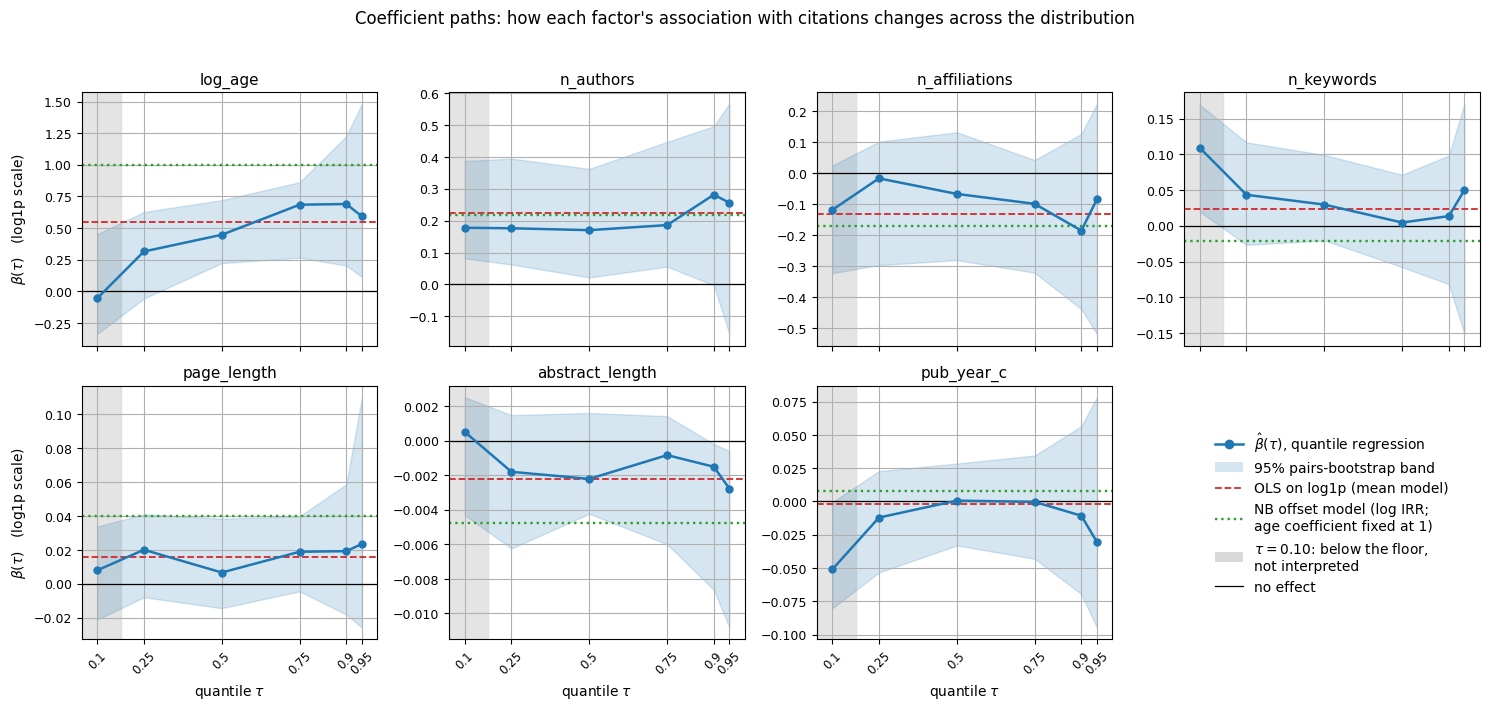

In [25]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

tau_arr = np.array(TAUS)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharex=True)

for ax, var in zip(axes.ravel(), qr_cols):
    i = qr_names.index(var)
    ax.axvspan(0.05, 0.175, color="0.85", alpha=0.7, zorder=0)          # flagged low-tau region
    ax.fill_between(tau_arr, pct_lo[i], pct_hi[i], color="#1f77b4", alpha=0.18, zorder=1)
    ax.plot(tau_arr, pt[i], "o-", color="#1f77b4", lw=1.8, ms=5, zorder=3)
    ax.axhline(0, color="black", lw=0.9, zorder=2)
    ax.axhline(ols_log1p.params[i], color="#d62728", ls="--", lw=1.3, zorder=2)
    ax.axhline(nb_ref[var] if var in feat_cols else 1.0, color="#2ca02c", ls=":", lw=1.7, zorder=2)
    ax.set_title(var, fontsize=11)
    ax.set_xticks(tau_arr); ax.set_xticklabels([f"{t:g}" for t in TAUS], fontsize=8.5, rotation=45)
    ax.set_xlim(0.05, 1.0); ax.tick_params(axis="y", labelsize=9)

for ax in axes[1]:
    ax.set_xlabel(r"quantile $\tau$")
axes[0, 0].set_ylabel(r"$\beta(\tau)$   (log1p scale)")
axes[1, 0].set_ylabel(r"$\beta(\tau)$   (log1p scale)")

legend_ax = axes.ravel()[-1]
legend_ax.axis("off")
legend_ax.legend(handles=[
    Line2D([], [], color="#1f77b4", marker="o", lw=1.8, label=r"$\hat\beta(\tau)$, quantile regression"),
    Patch(facecolor="#1f77b4", alpha=0.18, label="95% pairs-bootstrap band"),
    Line2D([], [], color="#d62728", ls="--", lw=1.3, label="OLS on log1p (mean model)"),
    Line2D([], [], color="#2ca02c", ls=":", lw=1.7,
           label="NB offset model (log IRR;\nage coefficient fixed at 1)"),
    Patch(facecolor="0.85", label=r"$\tau=0.10$: below the floor," + "\nnot interpreted"),
    Line2D([], [], color="black", lw=0.9, label="no effect"),
], loc="center", frameon=False, fontsize=10)

fig.suptitle("Coefficient paths: how each factor's association with citations changes across the distribution", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 2.16 Reading the paths

One panel at a time, on the interpretable range $\tau \in [0.25,\, 0.95]$.

**`log_age` rises, and never reaches what the offset assumes.** $0.315$, $0.447$, $0.684$, $0.690$, $0.592$ across the grid, significant at the median ($p = 0.0009$) and in the tail ($p = 0.0096$). A paper twice as old has $2^{0.4467} = 1.36$ times the citations at the median and $2^{0.69} = 1.61$ times in the tail, against the exactly $2.00$ the §2.4 offset asserts everywhere and the $1.039$ log-scale estimate from §2.3, also close to $2.00\times$. The quantile model disagrees with both at every level: accrual is clearly **sub-linear** in age, as Part 1's peak-and-decline shape predicts and a linear offset cannot represent. The upward slope says the sub-linearity bites harder near the median than in the tail: typical papers stop accruing citations, well-cited ones keep going.

**`n_authors` is the only paper-level factor with a visibly tail-shaped path.** Flat at $0.176$, $0.170$, $0.186$ across $\tau = 0.25,\, 0.50,\, 0.75$, then stepping to $0.281$ at $\tau = 0.90$ and $0.256$ at $\tau = 0.95$. Largest coefficient at every quantile, and the only band staying one side of zero over most of the range. §2.17 tests whether the step is real.

**`n_affiliations` is negative almost everywhere, never significantly.** $-0.017$, $-0.067$, $-0.099$, $-0.185$, $-0.084$; $p = 0.53$ at the median, $0.22$ in the tail. The NB line at $-0.171$ sits inside the band at every quantile, so the quantile model is consistent with the NB's marginal result ($p = 0.0615$) without confirming it. Conditional on author count, spreading the same authors across more institutions is not associated with more citations (§2.20 quantifies).

**`n_keywords` does nothing at any quantile.** $0.043$, $0.030$, $0.005$, $0.014$, $0.050$; $p \geq 0.32$ everywhere, agreeing with the NB ($p = 0.529$). Not a lever.

**`page_length` is flat and small, and does not reproduce the NB's result.** $0.020$, $0.007$, $0.019$, $0.019$, $0.024$; never significant ($p = 0.62$ at the median, $0.34$ in the tail). The NB put it at $0.0397$, $p = 0.0019$, one of that model's two strongest findings, sitting above the entire quantile path and outside the median band ($[-0.0144,\ 0.0384]$). Either the NB sees something the quantile model cannot, or its estimate rests on a handful of papers. §2.19 settles it.

**`abstract_length` is flat, negative, tiny, not significant.** $-0.0018$ to $-0.0028$ across the grid, $p = 0.16$ at the median. The NB's $-0.0048$ sits below the whole path and outside the median band ($[-0.0042,\ 0.0016]$), so the quantile model finds roughly half the effect. Not negligible in practice, since a one standard deviation longer abstract (38 words) goes with about 10% fewer citations at the median, but indistinguishable from zero at this sample size once the iid assumption is dropped.

**`pub_year_c` is flat at zero.** $0.001$ at the median, $-0.011$ in the tail, $p > 0.74$ throughout. §2.19 explains why.

Five of the six paper-level covariates are flat within noise. Only `n_authors` shows a shape a mean model would have missed, only `log_age` a slope large relative to its band. **The main finding of the coefficient-path exercise is that the paths are mostly flat**, so the NB's single-effect-per-covariate summary was not leaving much on the table here. What it got wrong was the age scaling and the stability of its own estimates, not the tail-versus-typical distinction.

## 2.17 Is the tail effect actually different from the median effect?

Eyeballing a path is not a test. "Does this variable matter more for breakout papers than for typical ones" has a precise formal version:

$$
H_0: \; \beta_j(0.90) = \beta_j(0.50)
\qquad\text{against}\qquad
H_1: \; \beta_j(0.90) \neq \beta_j(0.50)
$$

No closed-form standard error for that difference exists without assuming something about the joint distribution of the two estimators, so we take it from the bootstrap: every replicate refits *both* quantiles on the *same* resampled papers, so the bootstrap distribution of $\hat\beta_j(0.90) - \hat\beta_j(0.50)$ carries their correlation and gives the correct standard error.

We also report the smallest detectable gap, $2.80 \times \mathrm{SE}$, the effect size a two-sided 5% test attains 80% power against: the number that says whether a null result means "no effect" or "not enough data".

In [26]:
i5, i9  = TAUS.index(0.50), TAUS.index(0.90)
d_hat   = pt[:, i9] - pt[:, i5]
d_boot  = boot[:, :, i9] - boot[:, :, i5]        # paired: same resample at both quantiles
d_se    = d_boot.std(axis=0, ddof=1)
p_diff  = 2 * (1 - stats.norm.cdf(np.abs(d_hat / d_se)))

diff_tbl = pd.DataFrame({
    "b(0.50)": pt[:, i5], "b(0.90)": pt[:, i9], "difference": d_hat, "boot SE": d_se,
    "2.5%": np.percentile(d_boot, 2.5, axis=0), "97.5%": np.percentile(d_boot, 97.5, axis=0),
    "p (boot)": p_diff, "gap detectable at 80% power": 2.80 * d_se,
}, index=qr_names).drop(index="Intercept")

print("H0: beta(0.90) = beta(0.50)   (paired pairs bootstrap, B = %d)\n" % B_REP)
print(diff_tbl.round(4).to_string())
print(f"\nsmallest p-value across the seven covariates: {p_diff[1:].min():.3f}")
print("bootstrap corr(b(0.90), b(0.50)):",
      "  ".join(f"{qr_names[i]} {np.corrcoef(boot[:, i, i9], boot[:, i, i5])[0, 1]:.2f}"
               for i in range(1, len(qr_names))))

H0: beta(0.90) = beta(0.50)   (paired pairs bootstrap, B = 500)

                 b(0.50)  b(0.90)  difference  boot SE    2.5%  97.5%  p (boot)  gap detectable at 80% power
log_age           0.4467   0.6899      0.2432   0.2609 -0.2188 0.7484    0.3514                       0.7307
n_authors         0.1701   0.2814      0.1113   0.1342 -0.2020 0.3441    0.4069                       0.3757
n_affiliations   -0.0667  -0.1848     -0.1182   0.1581 -0.3893 0.2150    0.4548                       0.4426
n_keywords        0.0297   0.0136     -0.0161   0.0486 -0.1151 0.0687    0.7403                       0.1362
page_length       0.0067   0.0192      0.0126   0.0212 -0.0271 0.0520    0.5531                       0.0594
abstract_length  -0.0022  -0.0015      0.0007   0.0023 -0.0065 0.0027    0.7596                       0.0064
pub_year_c        0.0007  -0.0107     -0.0114   0.0322 -0.0616 0.0611    0.7244                       0.0902

smallest p-value across the seven covariates: 0.351
bootstrap 

**No covariate shows a significant difference between its tail effect and its median effect.** The smallest $p$-value across the seven is $0.351$, for `log_age`. `n_authors`, the most tail-shaped path, has a gap of $+0.111$, bootstrap standard error $0.134$, 95% interval $[-0.202,\ 0.344]$, $p = 0.407$. Every other $p$-value is above $0.45$.

A null result with a clear explanation. The power column says the test could only have detected a tail-minus-median gap of $0.376$ on the log scale for `n_authors`, the per-author effect being about **46% larger** in the tail than at the median. The observed gap is about 12%, so the study is underpowered here by roughly a factor of three, unsurprising when the $\tau = 0.90$ fit rests on the 56 papers above it (§2.12).

So the correct statement is **not** "the factors that drive high hitters are the same as the factors that drive typical papers". It is: *within the resolution of 582 papers from one journal, no paper-level covariate is shown to behave differently in the tail than at the median, and the effect sizes that would have been detectable are large ones.* A moderate tail-specific mechanism would have been invisible to this design. The point estimates hint at one for `n_authors` and the test cannot confirm it.

This also rehabilitates the NB's *coefficients*, if not its uncertainty estimates: if the effects genuinely do not differ across quantiles, one number per covariate is not obviously wrong. The problems with §2.4 lie in the age scaling (§2.16) and the stability of the estimates (§2.19).

## 2.18 How much do these factors explain?

Quantile regression has no $R^2$, because there is no sum of squares to decompose. The standard measure is Koenker and Machado's (1999) $R^1(\tau)$, built from the same check loss the estimator minimises:

$$
R^1(\tau) \;=\; 1 \;-\; \frac{\hat V(\tau)}{\tilde V(\tau)},
\qquad
\hat V(\tau) = \sum_i \rho_\tau\!\left(y_i - \mathbf{x}_i^\top \hat{\boldsymbol\beta}(\tau)\right),
\qquad
\tilde V(\tau) = \sum_i \rho_\tau\!\left(y_i - \hat\beta_0(\tau)\right)
$$

$\tilde V(\tau)$ is the check loss of the intercept-only model, whose fit is the unconditional $\tau$-quantile, so $R^1(\tau)$ is the proportion of quantile-specific loss removed by knowing the covariates. It lies in $[0,1]$ and is local to $\tau$: a model can fit the median well and the tail badly, or the reverse.

We report it per quantile three ways, full model, `log_age` alone, and the difference. The third column matters most for the client, isolating what the **paper-level** factors add once you know the paper's age, which is not something an editor can act on.

In [27]:
def check_loss(u, tau):
    return (u * (tau - (u < 0))).sum()

X_null = np.ones((len(fsr), 1))
X_age  = sm.add_constant(fsr[["log_age"]]).to_numpy()

r1 = pd.DataFrame([{
    "tau": tau,
    "R1 (age + paper factors)": 1 - check_loss(y_qr - X_qr  @ qr_fit(X_qr,  y_qr, tau), tau)
                                  / check_loss(y_qr - X_null @ qr_fit(X_null, y_qr, tau), tau),
    "R1 (age alone)":           1 - check_loss(y_qr - X_age  @ qr_fit(X_age,  y_qr, tau), tau)
                                  / check_loss(y_qr - X_null @ qr_fit(X_null, y_qr, tau), tau),
} for tau in TAUS]).set_index("tau")
r1.index = [f"{t:.2f}" for t in TAUS]
r1["added by paper factors"] = r1["R1 (age + paper factors)"] - r1["R1 (age alone)"]

print("Koenker-Machado R1(tau) = 1 - (check loss, full model) / (check loss, intercept only)\n")
print(r1.round(4).to_string())
print(f"\nOLS R^2 on the same response, for comparison: {ols_log1p.rsquared:.4f}")

q50_hat = np.expm1(X_qr @ qr_coef["tau=0.50"].to_numpy())
q90_hat = np.expm1(X_qr @ qr_coef["tau=0.90"].to_numpy())
print(f"\nMedian fitted Q(0.90)/Q(0.50) ratio across the 582 papers: {np.median(q90_hat / q50_hat):.1f}x")
print(f"Spread of fitted Q(0.90) across papers: {q90_hat.min():.1f} to {q90_hat.max():.1f} citations")

Koenker-Machado R1(tau) = 1 - (check loss, full model) / (check loss, intercept only)

      R1 (age + paper factors)  R1 (age alone)  added by paper factors
0.10                    0.0958          0.0719                  0.0238
0.25                    0.0632          0.0457                  0.0175
0.50                    0.0734          0.0613                  0.0121
0.75                    0.0924          0.0781                  0.0143
0.90                    0.1011          0.0835                  0.0176
0.95                    0.1131          0.0919                  0.0213

OLS R^2 on the same response, for comparison: 0.1360

Median fitted Q(0.90)/Q(0.50) ratio across the 582 papers: 5.3x
Spread of fitted Q(0.90) across papers: 1.6 to 110.3 citations


The numbers are small and should be taken at face value. Across the interpretable range the full model removes between 6.3% and 11.3% of the check loss, and most of that is age: `log_age` alone accounts for $0.046$ to $0.092$, so the six paper-level covariates together add only **1.2 to 2.1 percentage points**, $0.0121$ at the median and $0.0176$ in the tail where the question actually lives.

Two honest readings. First, the tail is marginally *more* predictable than the middle, not less: $R^1$ rises monotonically from $0.063$ at $\tau = 0.25$ to $0.113$ at $\tau = 0.95$, against the intuition that breakout papers are pure noise. But the paper-level increment is around 2% in the tail, so "more predictable" means "still almost entirely unpredictable, slightly less so".

Second, the residual conditional spread is enormous. The median paper's fitted $Q(0.90)$ is **5.3 times** its fitted $Q(0.50)$: two papers identical on every covariate here, including age, differ by more than a factor of five between a median and a 90th-percentile outcome. Roughly 98% of whatever separates an FSR high hitter from an ordinary FSR paper is not author count, affiliation count, keyword count, page length, abstract length or publication year.

On comparability: OLS on the same response gives $R^2 = 0.136$, larger than any $R^1$ here but a different quantity, computed against squared loss which the tail observations inflate heavily, so it flatters the mean model. Neither is reported as better than the other.

## 2.19 Robustness

Three checks, each aimed at a specific worry.

**(a) Outliers.** Quantile regression's resistance to extreme $y$ values should be tested, not asserted. We drop the five most-cited papers (678, 346, 334, 279 and 218 citations, together 0.9% of the sample) and refit both the quantile models and the §2.4 NB model on identical data, measuring how far each coefficient moves **in units of its own standard error**. Percentage change is the wrong metric, because a 90% change in a coefficient indistinguishable from zero means nothing.

**(b) Age handling.** Part 1 found a median citation peak at 10 years with a 4–20 year interquartile range, and 39% of papers still censored as not yet peaked. Papers younger than that have not had a chance to show what they are, so a slightly misspecified age control will leak age into the paper-level coefficients. We refit on `age >= 5` ($n = 515$) and `age >= 10` ($n = 439$).

**(c) The `pub_year_c` problem.** `age` is $2025 - \text{year}$ and `pub_year_c` is $\text{year} - \overline{\text{year}}$, related by an exact identity. We refit without it to see whether it has any independent role.

In [28]:
top5_cut = fsr["cited_by"].nlargest(5).min()
no_year  = [c for c in qr_cols if c != "pub_year_c"]

variants = {
    "full sample":      (fsr,                          qr_cols),
    "drop top 5 cited": (fsr[fsr["cited_by"] < top5_cut], qr_cols),
    "age >= 5":         (fsr[fsr["age"] >= 5],         qr_cols),
    "age >= 10":        (fsr[fsr["age"] >= 10],        no_year),
    "no pub_year_c":    (fsr,                          no_year),
}
print("citation counts dropped:", sorted(fsr["cited_by"].nlargest(5).tolist(), reverse=True))
print("n per variant:", {k: len(d) for k, (d, _) in variants.items()})
print(f"\npub_year_c + age takes {(fsr['pub_year_c'] + fsr['age']).round(6).nunique()} distinct value "
      f"({(fsr['pub_year_c'] + fsr['age']).iloc[0]:.4f}): pub_year_c IS age, negated and shifted.")
print(f"corr(log_age, pub_year_c) = {np.corrcoef(fsr['log_age'], fsr['pub_year_c'])[0, 1]:.3f}"
      f"   on age >= 10: {np.corrcoef(fsr.loc[fsr['age'] >= 10, 'log_age'], fsr.loc[fsr['age'] >= 10, 'pub_year_c'])[0, 1]:.3f}")

for tau in [0.50, 0.90]:
    out = {lab: pd.Series(qr_fit(sm.add_constant(d[cc]).to_numpy(), d["log1p_cited"].to_numpy(), tau),
                          index=["Intercept"] + cc)
           for lab, (d, cc) in variants.items()}
    print(f"\n--- quantile regression, tau = {tau:.2f} ---")
    print(pd.DataFrame(out).reindex(qr_names).round(4).to_string())

# the same perturbations applied to the NB mean model of 2.4
nb_tbl = pd.DataFrame({lab: sm.NegativeBinomial(d["cited_by"].to_numpy(), sm.add_constant(d[feat_cols]),
                                                offset=np.log(d["age"].to_numpy())).fit(disp=0).params
                       for lab, (d, _) in variants.items() if lab != "no pub_year_c"})
nb_p = pd.DataFrame({lab: sm.NegativeBinomial(d["cited_by"].to_numpy(), sm.add_constant(d[feat_cols]),
                                              offset=np.log(d["age"].to_numpy())).fit(disp=0).pvalues
                     for lab, (d, _) in variants.items() if lab != "no pub_year_c"})
print("\n--- Negative Binomial offset model (log IRR), same subsamples ---")
print(nb_tbl.round(4).to_string())
print("\nNB p-values, full sample vs the 5 most-cited papers removed:")
print(pd.DataFrame({"p (full)": nb_p["full sample"], "p (drop top 5)": nb_p["drop top 5 cited"]})
        .loc[feat_cols].round(4).to_string())
d5 = variants["drop top 5 cited"][0]
X5 = sm.add_constant(d5[qr_cols]).to_numpy(); y5 = d5["log1p_cited"].to_numpy()
nb_se = res_offset.bse
shift = pd.DataFrame({
    "NB (mean)":   (nb_tbl["drop top 5 cited"] - nb_tbl["full sample"]).loc[feat_cols] / nb_se[feat_cols],
    "QR tau=0.50": (pd.Series(qr_fit(X5, y5, 0.50), index=qr_names) - qr_coef["tau=0.50"]).loc[feat_cols]
                   / pd.Series(boot_se[:, TAUS.index(0.50)], index=qr_names).loc[feat_cols],
    "QR tau=0.90": (pd.Series(qr_fit(X5, y5, 0.90), index=qr_names) - qr_coef["tau=0.90"]).loc[feat_cols]
                   / pd.Series(boot_se[:, TAUS.index(0.90)], index=qr_names).loc[feat_cols],
})
print("\nCoefficient shift when 5 of 582 papers (0.9% of the sample) are removed,")
print("measured in standard errors of the coefficient itself:")
print(shift.map(lambda v: f"{v:+.2f} SE").to_string())

# does the headline author effect survive on mature papers only?
sub  = fsr[fsr["age"] >= 10]
X_m  = sm.add_constant(sub[no_year]).to_numpy(); y_m = sub["log1p_cited"].to_numpy()
rng_m = np.random.default_rng(SEED)
boot_m = np.empty((300, X_m.shape[1], 2))
for b in range(300):
    ix = rng_m.integers(0, len(sub), len(sub))
    for j, t in enumerate([0.50, 0.90]):
        boot_m[b, :, j] = qr_fit(X_m[ix], y_m[ix], t)
print(f"\nMature papers only (age >= 10, n = {len(sub)}), B = 300 bootstrap:")
for j, t in enumerate([0.50, 0.90]):
    bm = qr_fit(X_m, y_m, t); sm_ = boot_m[:, :, j].std(axis=0, ddof=1)
    print(f"  tau={t:.2f}  " + "   ".join(
        f"{v}={bm[(['Intercept']+no_year).index(v)]:+.4f} (SE {sm_[(['Intercept']+no_year).index(v)]:.4f})"
        for v in ["n_authors", "n_affiliations", "page_length"]))

citation counts dropped: [678, 346, 334, 279, 218]
n per variant: {'full sample': 582, 'drop top 5 cited': 577, 'age >= 5': 515, 'age >= 10': 439, 'no pub_year_c': 582}

pub_year_c + age takes 1 distinct value (15.6432): pub_year_c IS age, negated and shifted.
corr(log_age, pub_year_c) = -0.914   on age >= 10: -0.987

--- quantile regression, tau = 0.50 ---
                 full sample  drop top 5 cited  age >= 5  age >= 10  no pub_year_c
Intercept             0.3872            0.4252   -2.7097     1.6402         0.3617
log_age               0.4467            0.4417    1.7530     0.1699         0.4434
n_authors             0.1701            0.1666    0.2314     0.1519         0.1734
n_affiliations       -0.0667           -0.0480   -0.1246    -0.0434        -0.0669
n_keywords            0.0297            0.0257   -0.0284     0.0313         0.0294
page_length           0.0067            0.0038    0.0050    -0.0089         0.0070
abstract_length      -0.0022           -0.0022   -0.0032   


--- quantile regression, tau = 0.90 ---
                 full sample  drop top 5 cited  age >= 5  age >= 10  no pub_year_c
Intercept             0.9505            0.8473   -3.3480     3.5162         0.5550
log_age               0.6899            0.8391    2.2836     0.2220         0.8225
n_authors             0.2814            0.2385    0.2951     0.2585         0.2761
n_affiliations       -0.1848           -0.1884   -0.2224    -0.2687        -0.1705
n_keywords            0.0136            0.0349   -0.0539    -0.0410         0.0253
page_length           0.0192            0.0073    0.0434     0.0435         0.0199
abstract_length      -0.0015           -0.0022   -0.0019    -0.0107        -0.0017
pub_year_c           -0.0107            0.0141    0.0991        NaN            NaN

--- Negative Binomial offset model (log IRR), same subsamples ---
                 full sample  drop top 5 cited  age >= 5  age >= 10
const                -0.2759            0.0099   -0.0892     0.5815
n_authors


Mature papers only (age >= 10, n = 439), B = 300 bootstrap:
  tau=0.50  n_authors=+0.1519 (SE 0.1376)   n_affiliations=-0.0434 (SE 0.1362)   page_length=-0.0089 (SE 0.0201)
  tau=0.90  n_authors=+0.2585 (SE 0.1807)   n_affiliations=-0.2687 (SE 0.2131)   page_length=+0.0435 (SE 0.0242)


**(a) The outlier check is decisive, and it goes against the NB model.** Removing 5 papers out of 582 moves the NB coefficient on `page_length` by $2.81$ standard errors and on `pub_year_c` by $2.08$, and the consequences for inference are total: `page_length` goes from $p = 0.0019$ to $p = 0.755$, so the NB's second-strongest result disappears, while `pub_year_c` goes from $p = 0.384$ to $p = 0.0019$, so a result that did not exist appears. `n_authors` drops from $p = 0.0063$ to $p = 0.0665$; only `abstract_length` survives intact ($p = 0.0014 \to 0.0080$).

The same deletion moves the median quantile coefficients by **at most 0.21 standard errors** and the $\tau = 0.90$ coefficients by at most 0.77, the author count moving 0.04 SE at the median and 0.33 SE in the tail. That is the payoff of a check loss linear rather than quadratic in the residual: five papers cannot rewrite the answer. It also settles §2.16, since the NB's significant page-length effect was a property of five papers, not of the journal.

**(b) The author effect survives on mature papers.** `age >= 5` gives $0.231$ at the median and $0.295$ in the tail against the full-sample $0.170$ and $0.281$; `age >= 10` gives $0.152$ (SE $0.138$) and $0.259$ (SE $0.181$). Both sit comfortably inside the full-sample bootstrap interval, so the association is not an artefact of pooling young papers with old. The step up in the tail appears in all four specifications ($0.281$, $0.239$, $0.295$, $0.259$), stable in sign and rough size, and (per §2.17) never significantly different from the median effect.

`n_affiliations` becomes more negative on mature papers ($-0.269$ at $\tau = 0.90$, SE $0.213$) and `page_length` more positive ($+0.0435$, SE $0.0242$, $z \approx 1.8$). Neither crosses conventional significance and the mature subsample is 25% smaller, so these are drifts within noise.

**(c) `pub_year_c` is not a separate control, it is age again.** `pub_year_c + age` takes exactly one distinct value across all 582 papers ($15.6432$), since both are fixed functions of `year` with the window ending in 2025. No era effect here is separable from an age effect, because every paper was observed to the same calendar date. Including both `log_age` and `pub_year_c` therefore fits a flexible two-parameter curve in age, not age plus period, and neither coefficient is interpretable alone. The correlation is $-0.914$ on the full sample and $-0.987$ on `age >= 10`, which is why `log_age` takes wild values in the age-restricted columns ($1.75$ and $2.28$ on `age >= 5`, where both terms are retained).

Dropping `pub_year_c` barely changes the paper-level coefficients ($0.1734$ vs $0.1701$ for `n_authors` at the median, $0.2761$ vs $0.2814$ in the tail), so the substantive conclusions do not depend on the age parameterisation. Only the age coefficient does, and it should be read as one curve rather than two numbers. The age-conflation concern is real, but it lands on the age terms, not on the covariates an editorial team would act on.

## 2.20 From coefficients to citations

Coefficients on a $\log(1+y)$ scale are not something to hand an editorial board. This section converts them with the exact quantile-to-quantile transformation from §2.11 rather than the $\exp(\beta) - 1$ shortcut, evaluated at the average FSR paper, then repeats the exercise at age 10, the median citation peak age from Part 1.

One contrast needs separating out. `n_authors` is positive and `n_affiliations` negative and both are in the model at once, so "add a co-author" means different things depending on where the co-author comes from. An author at an institution already represented moves only `n_authors`; one at a new institution moves both, and the relevant effect is the **sum** of the two coefficients, for which the bootstrap gives a standard error directly.

In [29]:
x_bar = X_qr.mean(axis=0)

def q_at(x, tau):
    return np.expm1(x @ qr_coef[f"tau={tau:.2f}"].to_numpy())

deltas = {"n_authors": 1, "n_affiliations": 1, "n_keywords": 1,
          "page_length": 5, "abstract_length": round(fsr["abstract_length"].std())}
rows = []
for var, dlt in deltas.items():
    r = {"change": f"+{dlt:g} {var}"}
    for tau in [0.50, 0.90]:
        x2 = x_bar.copy(); x2[qr_names.index(var)] += dlt
        q0, q1 = q_at(x_bar, tau), q_at(x2, tau)
        r[f"Q({tau:.2f}) from"] = f"{q0:.2f}"
        r[f"Q({tau:.2f}) to"]   = f"{q1:.2f}"
        r[f"tau={tau:.2f}"]     = f"{100 * (q1 / q0 - 1):+.1f}%"
    rows.append(r)
print("Average FSR paper: age %.1f years, %.2f authors, %.1f affiliations, %.1f pages, %.0f-word abstract\n"
      % (fsr["age"].mean(), fsr["n_authors"].mean(), fsr["n_affiliations"].mean(),
         fsr["page_length"].mean(), fsr["abstract_length"].mean()))
print(pd.DataFrame(rows).set_index("change").to_string())

print("\nReading a coefficient as a percentage understates the effect at small counts:")
for tau in [0.50, 0.90]:
    b  = qr_coef.loc["n_authors", f"tau={tau:.2f}"]
    x2 = x_bar.copy(); x2[qr_names.index("n_authors")] += 1
    print(f"  +1 author at tau={tau:.2f}:  exp(beta)-1 = {100*np.expm1(b):+.1f}%    exact = {100*(q_at(x2, tau)/q_at(x_bar, tau)-1):+.1f}%")

la  = np.log(10)
pyc = float((fsr["pub_year_c"] + fsr["age"]).iloc[0]) - 10
print("\nFitted citation quantiles at age = 10 (the Part 1 median peak age), everything else at its mean:")
print("  n_authors" + "".join(f"  Q({t:.2f})" for t in TAUS))
for na in [1, 2, 3, 4]:
    x = x_bar.copy()
    x[qr_names.index("log_age")]    = la
    x[qr_names.index("pub_year_c")] = pyc
    x[qr_names.index("n_authors")]  = na
    print(f"  {na:9d}" + "".join(f"{q_at(x, t):9.1f}" for t in TAUS))
print(f"\nThe raw top-10% 'high hitter' cutoff used in 2.6 is {fsr['cited_by'].quantile(0.90):.0f} citations.")

Average FSR paper: age 16.8 years, 2.23 authors, 1.7 affiliations, 16.2 pages, 123-word abstract

                    Q(0.50) from Q(0.50) to tau=0.50 Q(0.90) from Q(0.90) to tau=0.90
change                                                                               
+1 n_authors                4.68       5.74   +22.5%        24.17      32.36   +33.8%
+1 n_affiliations           4.68       4.32    -7.8%        24.17      19.93   -17.6%
+1 n_keywords               4.68       4.85    +3.7%        24.17      24.52    +1.4%
+5 page_length              4.68       4.87    +4.1%        24.17      26.72   +10.5%
+38 abstract_length         4.68       4.23    -9.8%        24.17      22.78    -5.8%

Reading a coefficient as a percentage understates the effect at small counts:
  +1 author at tau=0.50:  exp(beta)-1 = +18.5%    exact = +22.5%
  +1 author at tau=0.90:  exp(beta)-1 = +32.5%    exact = +33.8%

Fitted citation quantiles at age = 10 (the Part 1 median peak age), everything else at its

In [30]:
ia, ifa = qr_names.index("n_authors"), qr_names.index("n_affiliations")
print("Adding a co-author at an EXISTING institution vs at a NEW one:\n")
for tau in [0.50, 0.90]:
    j = TAUS.index(tau)
    same = pt[ia, j]
    new  = pt[ia, j] + pt[ifa, j]
    bs_same, bs_new = boot[:, ia, j], boot[:, ia, j] + boot[:, ifa, j]
    print(f"  tau={tau:.2f}  same institution: {same:+.4f} (SE {bs_same.std(ddof=1):.4f}, "
          f"95% [{np.percentile(bs_same,2.5):+.4f}, {np.percentile(bs_same,97.5):+.4f}])"
          f"  -> {100*np.expm1(same):+.1f}%")
    print(f"            new institution : {new:+.4f} (SE {bs_new.std(ddof=1):.4f}, "
          f"95% [{np.percentile(bs_new,2.5):+.4f}, {np.percentile(bs_new,97.5):+.4f}])"
          f"  -> {100*np.expm1(new):+.1f}%")
print("\nAge scaling: a paper twice as old has this many times the citations (1+Q basis)")
print("  " + "  ".join(f"tau={t:.2f}: {2**qr_coef.loc['log_age', f'tau={t:.2f}']:.2f}x" for t in TAUS))
print("  the NB offset model assumes exactly 2.00x at every quantile.")
print("\nPower: the tail-minus-median gap we could have detected at 80% power, as a % difference")
print("  in the per-unit effect, vs the gap actually observed:")
for i in range(1, len(qr_names)):
    print(f"  {qr_names[i]:16s} detectable {100*np.expm1(2.80*d_se[i]):6.1f}%   observed {100*np.expm1(d_hat[i]):+7.1f}%")

Adding a co-author at an EXISTING institution vs at a NEW one:

  tau=0.50  same institution: +0.1701 (SE 0.0896, 95% [+0.0217, +0.3626])  -> +18.5%
            new institution : +0.1035 (SE 0.0855, 95% [-0.0455, +0.2787])  -> +10.9%
  tau=0.90  same institution: +0.2814 (SE 0.1312, 95% [-0.0029, +0.4965])  -> +32.5%
            new institution : +0.0966 (SE 0.1173, 95% [-0.1177, +0.3446])  -> +10.1%

Age scaling: a paper twice as old has this many times the citations (1+Q basis)
  tau=0.10: 0.96x  tau=0.25: 1.24x  tau=0.50: 1.36x  tau=0.75: 1.61x  tau=0.90: 1.61x  tau=0.95: 1.51x
  the NB offset model assumes exactly 2.00x at every quantile.

Power: the tail-minus-median gap we could have detected at 80% power, as a % difference
  in the per-unit effect, vs the gap actually observed:
  log_age          detectable  107.6%   observed   +27.5%
  n_authors        detectable   45.6%   observed   +11.8%
  n_affiliations   detectable   55.7%   observed   -11.1%
  n_keywords       detectable 

Three things fall out of these numbers.

**Author count is the only practically meaningful factor, and it is modest.** One extra author is worth about 22% more citations for a typical paper and about 34% at the 90th percentile of its conditional distribution. Real, but not the factor of five or more separating an ordinary paper from a high hitter (§2.18).

**Where the co-author comes from appears to matter more than that they exist.** At the median, a co-author at an institution already on the paper is worth $+18.5\%$ against $+10.9\%$ for one at a new institution; in the tail, $+32.5\%$ against $+10.1\%$. Both sums have wide intervals and the difference is not formally tested, so this is a pattern to note rather than one to act on. It does cut against the common assumption that cross-institutional collaboration drives citations, at least within this journal.

**Nothing else moves the needle**, and none of it is significant: a keyword $+3.7\%$ at the median and $+1.4\%$ in the tail; five extra pages $+4.1\%$ and $+10.5\%$, with §2.19 showing the mean model's apparently strong page-length result was carried by five papers; a standard-deviation longer abstract (38 words) about 10% fewer citations at the median, not trivial in size but not distinguishable from zero.

The age-10 table is the most useful output for an editor. At the Part 1 median peak age, an otherwise average paper's fitted 90th percentile runs from **12.6 citations solo-authored to 30.6 with four authors**, against §2.8.1's top-10% cutoff of 26: the solo paper never clears the bar even at the top of its own conditional distribution, the four-author one does. That is the most discrimination anything in this model achieves, and the author coefficient's interval makes even it provisional. The negative $Q(0.10)$ for a solo-authored paper is the §2.12 floor problem, exactly where predicted.

## 2.21 What this means for FSR

Question D has two halves: **when** to judge a paper, and **what to look for**. Part 1 answered the first with a Kaplan-Meier median time to citation peak of 10 years, 39% of papers still censored as not yet peaked, and a raw interquartile range of 4 to 20 years that did not survive §1.7's robustness work and should be read as an upper bound on dispersion rather than an estimate of it. This section answers the second, and the answer is largely negative.

### When to judge

The age path here sharpens Part 1's median. Citation accrual is strongly sub-linear: doubling a paper's age multiplies its citations by about $1.36$ at the median and $1.61$ at $\tau = 0.90$, never the $2.00$ the Negative Binomial offset assumes. Each marginal year buys less, the arithmetic signature of Part 1's peak-and-decline shape. Two consequences:

- **Judgement before about 10 years is premature for most papers.** Half have not peaked by then, and with 39% censored at the cut-off the dispersion around that median is at least as wide as 4 to 20 years. Sub-linear, quantile-dependent scaling also means an early count cannot be extrapolated forward with a fixed multiplier.
- **The papers most likely to be misjudged early are the ones the client cares about.** The age coefficient is larger at $\tau = 0.90$ than at $\tau = 0.50$ ($0.690$ versus $0.447$), so well-cited papers keep accruing for longer and an early call is systematically less reliable for tail papers than for median ones. The difference is not significant (§2.17), but the sign holds across the whole upper half of the grid.

### What to look for

Of the six paper-level factors available, **one carries any signal and five do not**:

| Factor | Typical paper ($\tau = 0.50$) | Tail ($\tau = 0.90$) | Verdict |
|---|---|---|---|
| `n_authors` | $+22.5\%$ per author | $+33.8\%$ per author | Consistently positive, borderline significant, largest effect in the model |
| `n_affiliations` | $-7.8\%$ | $-17.6\%$ | Negative throughout, never significant |
| `page_length` | $+4.1\%$ per 5 pages | $+10.5\%$ per 5 pages | Not significant; the NB's significant result was 5 papers |
| `abstract_length` | $-9.8\%$ per 38 words | $-5.8\%$ | Not significant once the iid assumption is dropped |
| `n_keywords` | $+3.7\%$ | $+1.4\%$ | Flat at zero at every quantile |
| `pub_year_c` | $\approx 0$ | $\approx 0$ | Not identifiable separately from age |

And on whether high-hitter factors differ from typical-paper factors: **no covariate is shown to behave differently in the tail**, smallest $p = 0.351$. `n_authors` steps from about $0.18$ to $0.28$ in the top decile, the one tail-shaped result, and the test cannot separate it from noise: only a gap of about 46% in the per-author effect was detectable, and the observed gap is about 12%.

### How much should the editorial team expect from acting on this?

Very little, and this is the most important number in the section. Net of age, the six paper-level factors reduce the quantile-specific loss by **1.2 percentage points at the median and 1.8 in the tail** ($R^1$ increments, §2.18), and conditional on everything in the model a paper's 90th-percentile outcome is still about 5.3 times its median. Roughly 98% of what separates an FSR high hitter from an ordinary paper is not author count, affiliation count, keyword count, page length, abstract length or publication year.

That is not a failure of the model but a finding: **the metadata an editor sees at submission does not predict citation outcomes.** Concretely:

1. **Do not build a metadata screen.** No combination of these variables identifies high hitters well enough to act on, and §2.8.1's confusion matrix showed the same for the mean model. Such a heuristic would be close to random.
2. **Do not impose format rules expecting citations.** Keyword counts are flat at zero everywhere, page-length and abstract-length effects are not significant, and the page-length result evaporated when five papers were removed. Minimum-keyword or minimum-length policies have no support here.
3. **Multi-author submissions are worth modestly more citations, and are not a policy lever anyway**, since an editor cannot add authors to a submitted paper. The finding is descriptive: FSR's more-cited papers tend to have more authors, plausibly through larger citing networks, broader scope or more promotion capacity. If it is a lever at all, it is a commissioning one.
4. **Judge late, and expect to be wrong.** Ten years is the median time to peak, so earlier assessments are provisional for most papers and least reliable for the tail papers most worth identifying.
5. **The real drivers are elsewhere.** These six variables are structural metadata, carrying nothing about topic, method, data source, writing quality, author standing or post-publication promotion. A 2% incremental fit says the answer lies in content and dissemination, which is where the rest of the project should look.

### What this analysis can and cannot support

It can support statements about **association within FSR's published corpus**: which observable features co-occur with higher citation quantiles among 582 papers in one journal, observed to the end of 2025.

It cannot support causal statements. This is observational data with no randomisation, no control group and no identification strategy. Author count is chosen rather than assigned, and correlates with unmeasured things (project scope, funding, seniority, network size) that plausibly drive citations on their own. The brief is right that this evidence base is "rarely causal" (Kousha and Thelwall, 2024). "Papers with more authors are cited more" is supported; "adding an author would cause more citations" is not.

Three further limits worth stating plainly:

- **Single journal, single field.** FSR is a Diamond Open Access journal in personal financial planning, and nothing here transfers to other journals or fields without checking.
- **Survivorship.** This is the published corpus. Rejected submissions are not observed, so every association is conditional on having been accepted by FSR.
- **Power.** At $N = 582$ with 56 papers above the $\tau = 0.90$ fit, moderate tail-specific effects are not detectable. Pooling the other two journals in `master_dataset.csv`, or extending the FSR back-catalogue, would give the §2.17 test enough power to distinguish a tail effect from a location shift, and is the one change that would most improve this analysis.